# **Food Demand Forecasting and Cost Sensitive Inventory Optimization Using ML**

Installation of Machine Learning Dependencies

In [ ]:
# Install LightGBM and XGBoost dependencies
%pip -q install lightgbm xgboost

Importing Required Libraries and Packages

In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

from IPython.display import display

# Import machine learning models and utilities
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Import boosting algorithms
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Configure display and visualization settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

Loading Training, Testing and Supporting Datasets

In [ ]:
# Load training, test and supporting datasets
TRAIN_PATH = "/content/train.csv"
TEST_PATH = "/content/test.csv"
MEAL_PATH = "/content/meal_info.csv"
CENTER_PATH = "/content/fulfilment_center_info.csv"
SAMPLE_PATH = "/content/sample_submission.csv"

df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)
df_meal = pd.read_csv(MEAL_PATH)
df_center = pd.read_csv(CENTER_PATH)
df_sample = pd.read_csv(SAMPLE_PATH)

# Inspect dataset dimensions
print("Train shape:", df_train.shape)
print("Test shape:", df_test.shape)
print("Meal info shape:", df_meal.shape)
print("Fulfilment center shape:", df_center.shape)
print("Sample submission shape:", df_sample.shape)

# Preview training and test datasets
display(df_train.head())
display(df_test.head())

Train shape: (456548, 9)
Test shape: (32573, 8)
Meal info shape: (51, 3)
Fulfilment center shape: (77, 5)
Sample submission shape: (32573, 2)


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders
0,1379560,1,55,1885,136.83,152.29,0,0,177
1,1466964,1,55,1993,136.83,135.83,0,0,270
2,1346989,1,55,2539,134.86,135.86,0,0,189
3,1338232,1,55,2139,339.50,437.53,0,0,54
4,1448490,1,55,2631,243.50,242.50,0,0,40


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured
0,1028232,146,55,1885,158.11,159.11,0,0
1,1127204,146,55,1993,160.11,159.11,0,0
2,1212707,146,55,2539,157.14,159.14,0,0
3,1082698,146,55,2631,162.02,162.02,0,0
4,1400926,146,55,1248,163.93,163.93,0,0


## **Exploratory Data Analysis**

Initial Dataset Inspection and Structural Analysis

In [ ]:
# Inspect dataset structure and data quality
print("TRAIN COLUMNS")
print(df_train.columns.tolist())

print("\nTEST COLUMNS")
print(df_test.columns.tolist())

print("\nTRAIN INFO")
df_train.info()

# Preview supporting datasets
print("\nMEAL INFO")
display(df_meal.head())

print("\nFULFILMENT CENTER INFO")
display(df_center.head())

# Check missing values
print("\nMISSING VALUES - TRAIN")
display(df_train.isnull().sum())

print("\nMISSING VALUES - TEST")
display(df_test.isnull().sum())

# Check duplicate records
print("\nDUPLICATES")
print("Train duplicates:", df_train.duplicated().sum())
print("Test duplicates:", df_test.duplicated().sum())

TRAIN COLUMNS
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured', 'num_orders']

TEST COLUMNS
['id', 'week', 'center_id', 'meal_id', 'checkout_price', 'base_price', 'emailer_for_promotion', 'homepage_featured']

TRAIN INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 456548 entries, 0 to 456547
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   id                     456548 non-null  int64  
 1   week                   456548 non-null  int64  
 2   center_id              456548 non-null  int64  
 3   meal_id                456548 non-null  int64  
 4   checkout_price         456548 non-null  float64
 5   base_price             456548 non-null  float64
 6   emailer_for_promotion  456548 non-null  int64  
 7   homepage_featured      456548 non-null  int64  
 8   num_orders             456548 non-null  int64  
dtypes: float64(2),

,meal_id,category,cuisine
0,1885,Beverages,Thai
1,1993,Beverages,Thai
2,2539,Beverages,Thai
3,1248,Beverages,Indian
4,2631,Beverages,Indian



FULFILMENT CENTER INFO


,center_id,city_code,region_code,center_type,op_area
0,11,679,56,TYPE_A,3.7
1,13,590,56,TYPE_B,6.7
2,124,590,56,TYPE_C,4.0
3,66,648,34,TYPE_A,4.1
4,94,632,34,TYPE_C,3.6



MISSING VALUES - TRAIN


,0
id,0
week,0
center_id,0
meal_id,0
checkout_price,0
base_price,0
emailer_for_promotion,0
homepage_featured,0
num_orders,0



MISSING VALUES - TEST


,0
id,0
week,0
center_id,0
meal_id,0
checkout_price,0
base_price,0
emailer_for_promotion,0
homepage_featured,0



DUPLICATES
Train duplicates: 0
Test duplicates: 0


Integration of Meal and Fulfilment Center Datasets

In [ ]:
# Merge meal and fulfilment center details into train and test datasets
df_train_merged = (
    df_train
    .merge(df_meal, on="meal_id", how="left")
    .merge(df_center, on="center_id", how="left")
)

df_test_merged = (
    df_test
    .merge(df_meal, on="meal_id", how="left")
    .merge(df_center, on="center_id", how="left")
)

# Verify merged datasets and check for missing values
print("Merged train shape:", df_train_merged.shape)
print("Merged test shape:", df_test_merged.shape)

print("\nMissing values after merge:")
print("Train:", df_train_merged.isnull().sum().sum())
print("Test :", df_test_merged.isnull().sum().sum())

display(df_train_merged.head())

Merged train shape: (456548, 15)
Merged test shape: (32573, 14)

Missing values after merge:
Train: 0
Test : 0


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,category,cuisine,city_code,region_code,center_type,op_area
0,1379560,1,55,1885,136.83,152.29,0,0,177,Beverages,Thai,647,56,TYPE_C,2.0
1,1466964,1,55,1993,136.83,135.83,0,0,270,Beverages,Thai,647,56,TYPE_C,2.0
2,1346989,1,55,2539,134.86,135.86,0,0,189,Beverages,Thai,647,56,TYPE_C,2.0
3,1338232,1,55,2139,339.50,437.53,0,0,54,Beverages,Indian,647,56,TYPE_C,2.0
4,1448490,1,55,2631,243.50,242.50,0,0,40,Beverages,Indian,647,56,TYPE_C,2.0


Date Conversion and Temporal Feature Extraction

In [ ]:
# Convert week numbers into calendar dates
BASE_DATE = pd.Timestamp("2017-01-02")

for df in [df_train_merged, df_test_merged]:
    df["week_number"] = df["week"].astype(int)
    df["date"] = BASE_DATE + pd.to_timedelta((df["week_number"] - 1) * 7, unit="D")

# Sort datasets chronologically by center and meal
df_train_merged = df_train_merged.sort_values(
    ["center_id", "meal_id", "week_number"]
).reset_index(drop=True)

df_test_merged = df_test_merged.sort_values(
    ["center_id", "meal_id", "week_number"]
).reset_index(drop=True)

# Verify the training date range
print("Date range in train:")
print(df_train_merged["date"].min(), "to", df_train_merged["date"].max())

display(df_train_merged.head())

Date range in train:
2017-01-02 00:00:00 to 2019-10-07 00:00:00


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,category,cuisine,city_code,region_code,center_type,op_area,week_number,date
0,1436842,1,10,1062,181.39,181.39,0,0,865,Beverages,Italian,590,56,TYPE_B,6.3,1,2017-01-02
1,1205013,2,10,1062,183.36,182.36,0,0,782,Beverages,Italian,590,56,TYPE_B,6.3,2,2017-01-09
2,1447751,3,10,1062,184.36,182.36,0,0,851,Beverages,Italian,590,56,TYPE_B,6.3,3,2017-01-16
3,1014968,4,10,1062,182.36,183.36,0,0,1202,Beverages,Italian,590,56,TYPE_B,6.3,4,2017-01-23
4,1003563,5,10,1062,183.39,181.39,0,0,958,Beverages,Italian,590,56,TYPE_B,6.3,5,2017-01-30


Exploratory Analysis of Numerical Feature Distributions

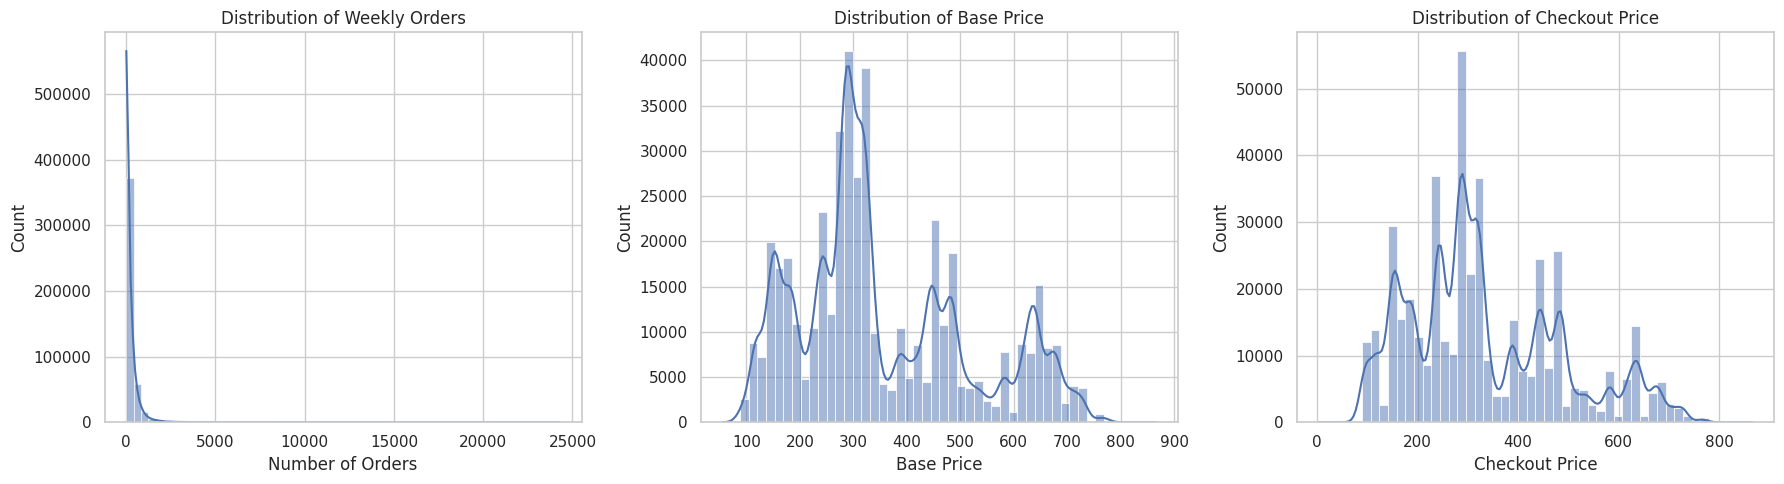

In [ ]:
# Visualize distributions of key numerical features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_train_merged["num_orders"], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Weekly Orders")
axes[0].set_xlabel("Number of Orders")

sns.histplot(df_train_merged["base_price"], bins=50, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Base Price")
axes[1].set_xlabel("Base Price")

sns.histplot(df_train_merged["checkout_price"], bins=50, kde=True, ax=axes[2])
axes[2].set_title("Distribution of Checkout Price")
axes[2].set_xlabel("Checkout Price")

plt.tight_layout()
plt.show()

Weekly Food Demand Trend Analysis

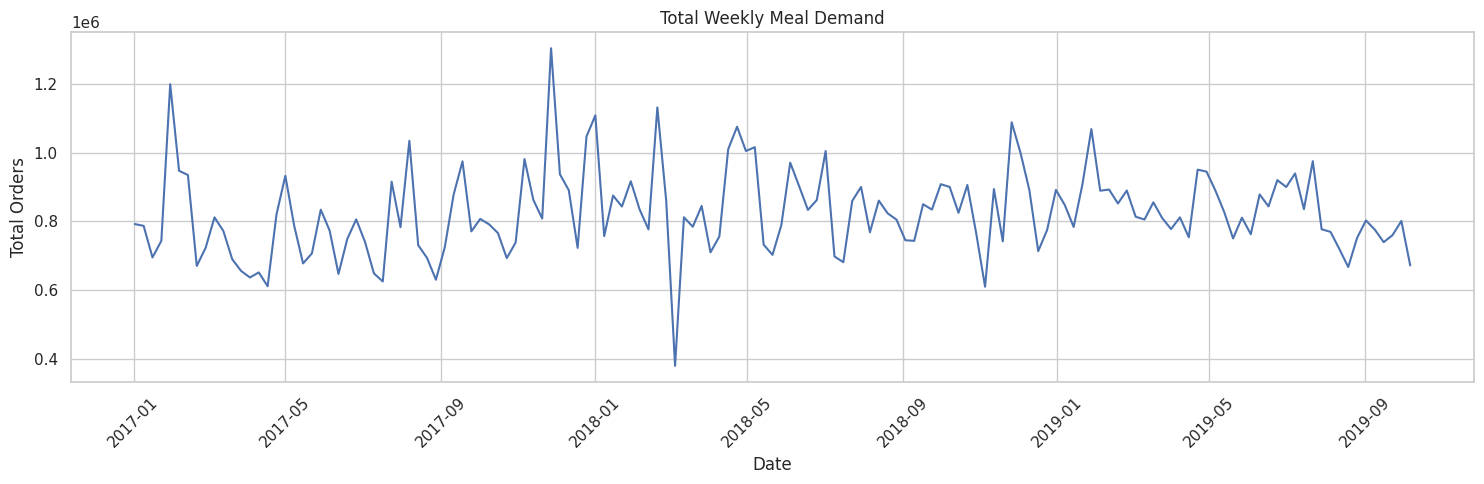

In [ ]:
# Aggregate total demand across all meal-center combinations by week
weekly_demand = (
    df_train_merged.groupby("date")["num_orders"]
    .sum()
    .reset_index()
)

# Plot overall weekly demand trend
plt.figure(figsize=(15, 5))
plt.plot(weekly_demand["date"], weekly_demand["num_orders"])
plt.title("Total Weekly Meal Demand")
plt.xlabel("Date")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Monthly Food Demand Trend Analysis

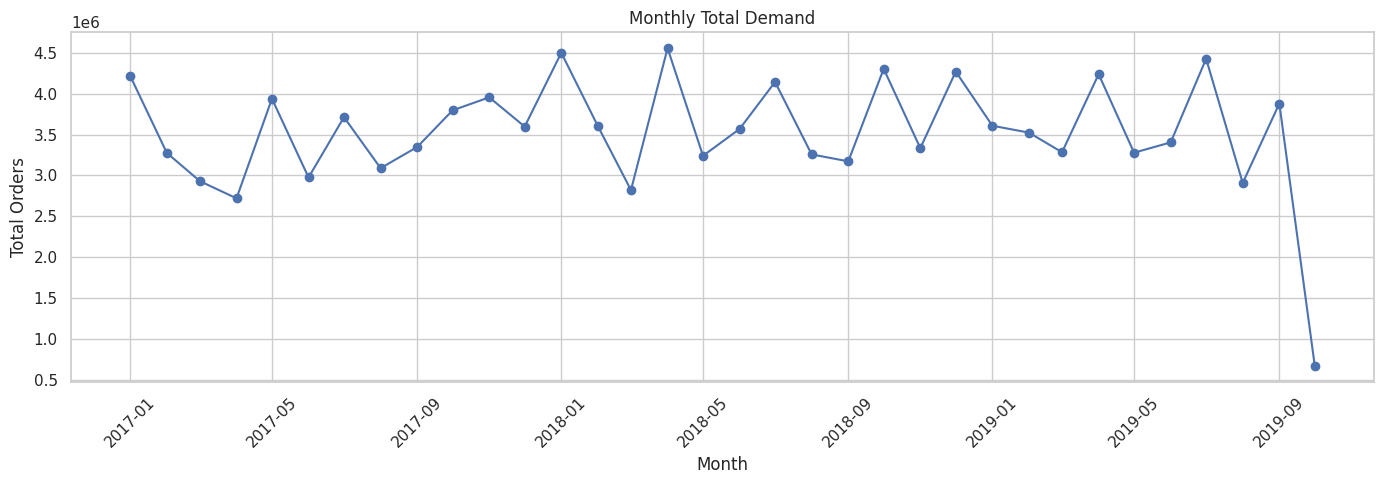

In [ ]:
# Aggregate total demand by month
monthly_demand = (
    df_train_merged.groupby(df_train_merged["date"].dt.to_period("M"))["num_orders"]
    .sum()
    .reset_index()
)

monthly_demand["date"] = monthly_demand["date"].dt.to_timestamp()

# Plot monthly demand trend
plt.figure(figsize=(14, 5))
plt.plot(monthly_demand["date"], monthly_demand["num_orders"], marker="o")
plt.title("Monthly Total Demand")
plt.xlabel("Month")
plt.ylabel("Total Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Food Demand Analysis by Category and Cuisine

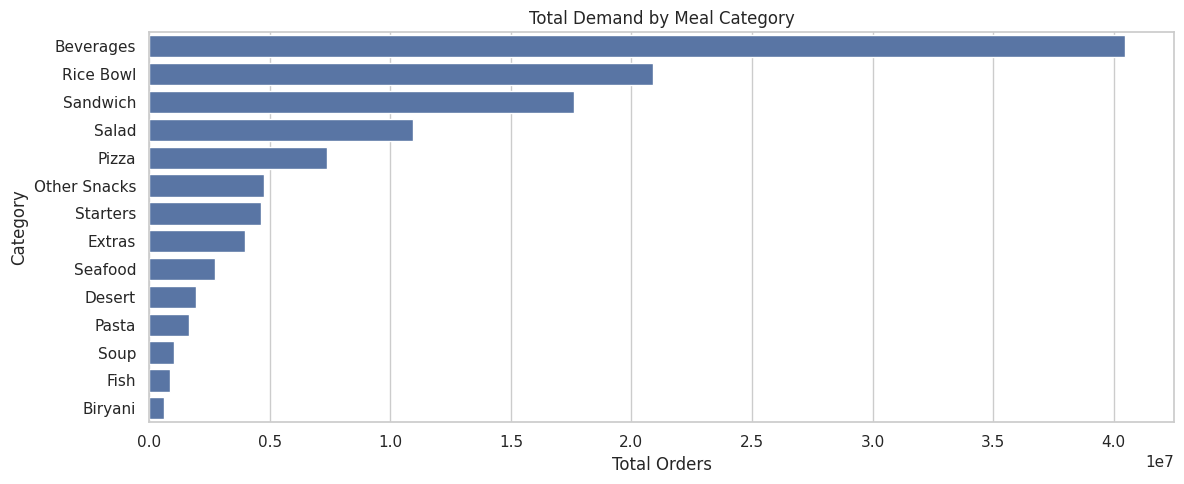

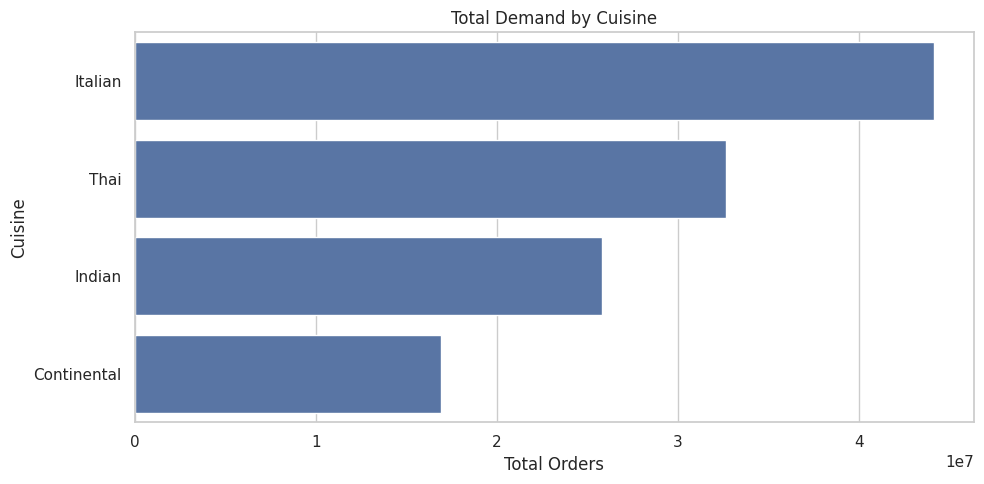

In [ ]:
# Aggregate demand by meal category
category_demand = (
    df_train_merged.groupby("category")["num_orders"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))
sns.barplot(x=category_demand.values, y=category_demand.index)
plt.title("Total Demand by Meal Category")
plt.xlabel("Total Orders")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

# Aggregate demand by cuisine
cuisine_demand = (
    df_train_merged.groupby("cuisine")["num_orders"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=cuisine_demand.values, y=cuisine_demand.index)
plt.title("Total Demand by Cuisine")
plt.xlabel("Total Orders")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()

Impact of Promotional Campaigns on Food Demand

Emailer promotion impact:


,mean,median,sum,count
emailer_for_promotion,,,,
0,229.262883,123.0,96175321,419498
1,631.097544,338.0,23382164,37050


Homepage featured impact:


,mean,median,sum,count
homepage_featured,,,,
0,221.050040,123.0,89899504,406693
1,594.884786,350.0,29657981,49855


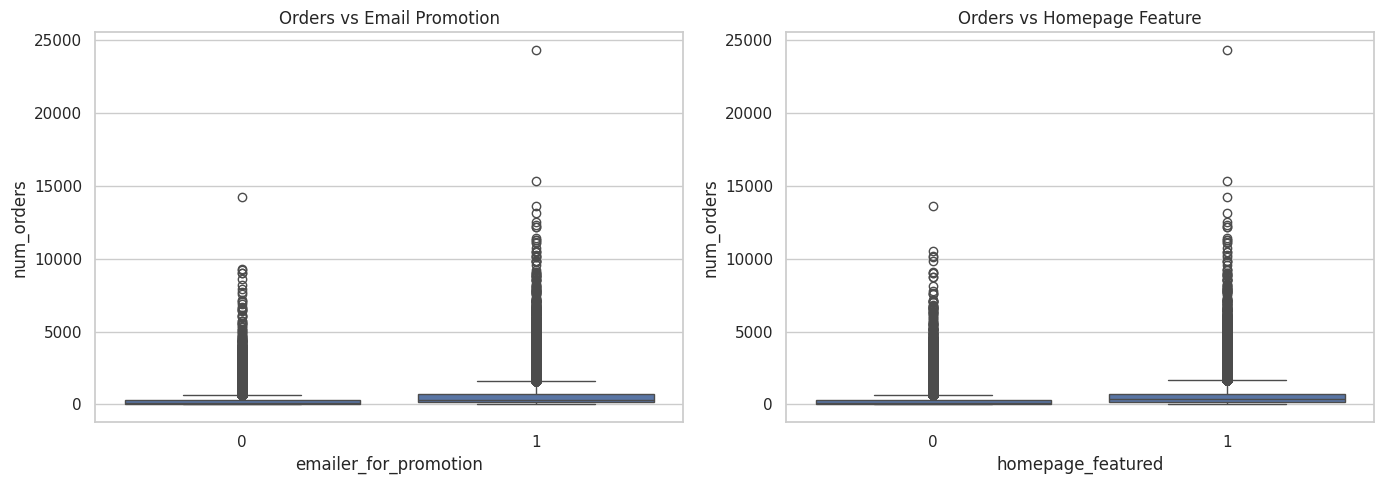

In [ ]:
# Analyze demand patterns across promotional activities
promotion_summary = (
    df_train_merged.groupby("emailer_for_promotion")["num_orders"]
    .agg(["mean", "median", "sum", "count"])
)

homepage_summary = (
    df_train_merged.groupby("homepage_featured")["num_orders"]
    .agg(["mean", "median", "sum", "count"])
)

print("Emailer promotion impact:")
display(promotion_summary)

print("Homepage featured impact:")
display(homepage_summary)

# Compare order distributions across promotional conditions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df_train_merged,
    x="emailer_for_promotion",
    y="num_orders",
    ax=axes[0]
)
axes[0].set_title("Orders vs Email Promotion")

sns.boxplot(
    data=df_train_merged,
    x="homepage_featured",
    y="num_orders",
    ax=axes[1]
)
axes[1].set_title("Orders vs Homepage Feature")

plt.tight_layout()
plt.show()

Relationship Between Meal Pricing and Demand

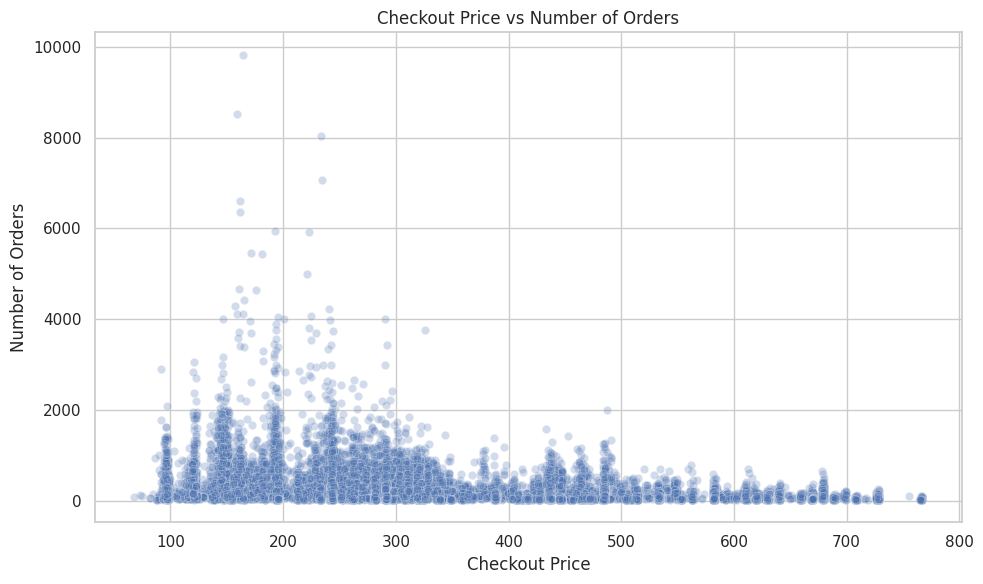

In [ ]:
# Sample records for clearer visualization
sample_plot = df_train_merged.sample(
    min(20000, len(df_train_merged)),
    random_state=RANDOM_STATE
)

# Examine the relationship between checkout price and demand
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=sample_plot,
    x="checkout_price",
    y="num_orders",
    alpha=0.25
)
plt.title("Checkout Price vs Number of Orders")
plt.xlabel("Checkout Price")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

Demand Distribution Across Cities and Fulfilment Centers

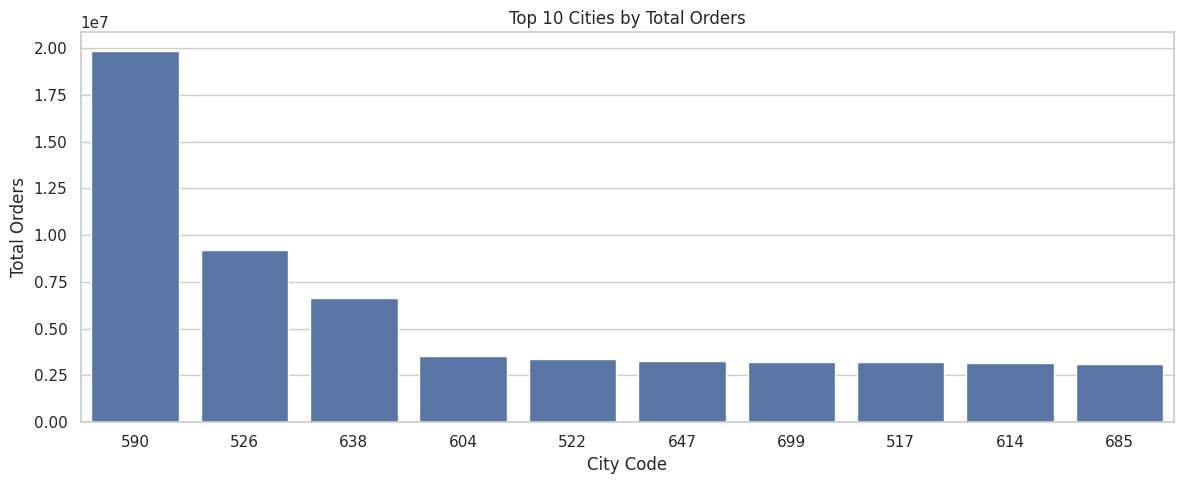

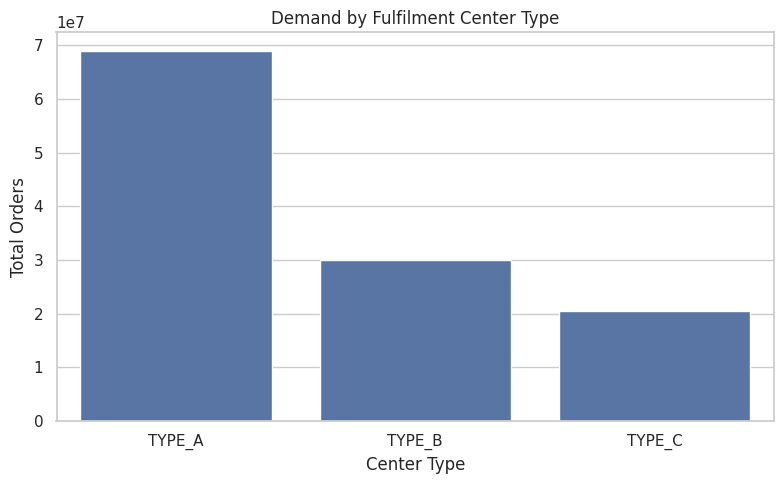

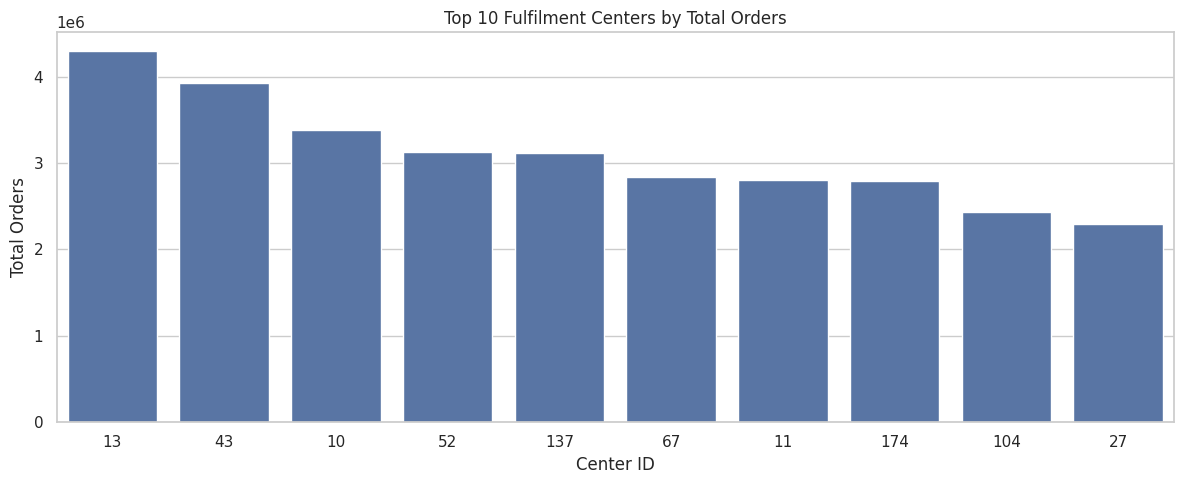

In [ ]:
# Identify cities with the highest total demand
top_cities = (
    df_train_merged.groupby("city_code")["num_orders"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_cities.index.astype(str), y=top_cities.values)
plt.title("Top 10 Cities by Total Orders")
plt.xlabel("City Code")
plt.ylabel("Total Orders")
plt.tight_layout()
plt.show()

# Compare demand across fulfilment center types
center_type_demand = (
    df_train_merged.groupby("center_type")["num_orders"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
sns.barplot(x=center_type_demand.index, y=center_type_demand.values)
plt.title("Demand by Fulfilment Center Type")
plt.xlabel("Center Type")
plt.ylabel("Total Orders")
plt.tight_layout()
plt.show()

# Identify the highest-demand fulfilment centers
top_centers = (
    df_train_merged.groupby("center_id")["num_orders"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 5))
sns.barplot(x=top_centers.index.astype(str), y=top_centers.values)
plt.title("Top 10 Fulfilment Centers by Total Orders")
plt.xlabel("Center ID")
plt.ylabel("Total Orders")
plt.tight_layout()
plt.show()

Correlation Analysis of Numerical Features

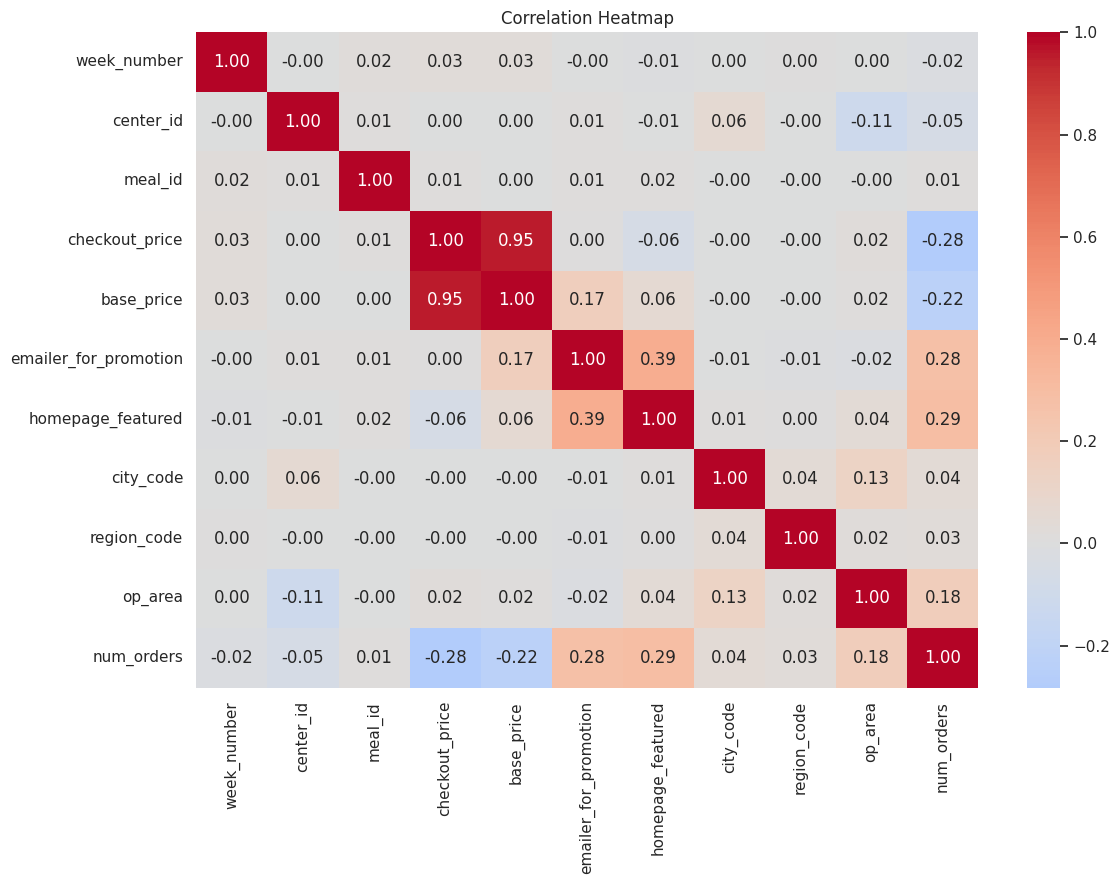

In [ ]:
# Examine correlations among numerical features
numeric_cols = [
    "week_number",
    "center_id",
    "meal_id",
    "checkout_price",
    "base_price",
    "emailer_for_promotion",
    "homepage_featured",
    "city_code",
    "region_code",
    "op_area",
    "num_orders"
]

corr = df_train_merged[numeric_cols].corr()

# Visualize the correlation matrix
plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## **Feature Engineering**

Calendar-Based and Price-Related Feature Engineering

In [ ]:
# Engineer price-related and calendar features
def add_calendar_features(df):
    df = df.copy()

    df["price_diff"] = df["base_price"] - df["checkout_price"]

    df["discount_percentage"] = np.where(
        df["base_price"] != 0,
        (df["price_diff"] / df["base_price"]) * 100,
        0
    )

    df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)
    df["month"] = df["date"].dt.month
    df["year"] = df["date"].dt.year
    df["time_index"] = df["week_number"]

    return df


# Apply feature engineering to training and test datasets
df_train_fe = add_calendar_features(df_train_merged)
df_test_fe = add_calendar_features(df_test_merged)

print("Feature engineering completed.")
display(df_train_fe.head())

Feature engineering completed.


,id,week,center_id,meal_id,checkout_price,base_price,emailer_for_promotion,homepage_featured,num_orders,category,cuisine,city_code,region_code,center_type,op_area,week_number,date,price_diff,discount_percentage,week_of_year,month,year,time_index
0,1436842,1,10,1062,181.39,181.39,0,0,865,Beverages,Italian,590,56,TYPE_B,6.3,1,2017-01-02,0.0,0.000000,1,1,2017,1
1,1205013,2,10,1062,183.36,182.36,0,0,782,Beverages,Italian,590,56,TYPE_B,6.3,2,2017-01-09,-1.0,-0.548366,2,1,2017,2
2,1447751,3,10,1062,184.36,182.36,0,0,851,Beverages,Italian,590,56,TYPE_B,6.3,3,2017-01-16,-2.0,-1.096732,3,1,2017,3
3,1014968,4,10,1062,182.36,183.36,0,0,1202,Beverages,Italian,590,56,TYPE_B,6.3,4,2017-01-23,1.0,0.545375,4,1,2017,4
4,1003563,5,10,1062,183.39,181.39,0,0,958,Beverages,Italian,590,56,TYPE_B,6.3,5,2017-01-30,-2.0,-1.102597,5,1,2017,5


Historical Lag and Rolling-Window Feature Generation

In [ ]:
# Generate historical lag and rolling-window features
GROUP_COLS = ["center_id", "meal_id"]

df_train_fe = df_train_fe.sort_values(
    GROUP_COLS + ["week_number"]
).reset_index(drop=True)

grouped_orders = df_train_fe.groupby(GROUP_COLS)["num_orders"]

# Create lag features from previous observations
for lag in [1, 2, 3, 4]:
    df_train_fe[f"lag_{lag}"] = grouped_orders.shift(lag)

# Calculate rolling demand statistics using past observations
df_train_fe["rolling_mean_4"] = (
    df_train_fe.groupby(GROUP_COLS)["num_orders"]
    .transform(lambda s: s.shift(1).rolling(window=4, min_periods=1).mean())
)

df_train_fe["rolling_std_4"] = (
    df_train_fe.groupby(GROUP_COLS)["num_orders"]
    .transform(lambda s: s.shift(1).rolling(window=4, min_periods=2).std())
)

lag_cols = [
    "lag_1", "lag_2", "lag_3", "lag_4",
    "rolling_mean_4", "rolling_std_4"
]

print("Lag and rolling features created.")
display(df_train_fe[GROUP_COLS + ["week_number", "num_orders"] + lag_cols].head(15))

Lag and rolling features created.


,center_id,meal_id,week_number,num_orders,lag_1,lag_2,lag_3,lag_4,rolling_mean_4,rolling_std_4
0,10,1062,1,865,NaN,NaN,NaN,NaN,NaN,NaN
1,10,1062,2,782,865.0,NaN,NaN,NaN,865.000000,NaN
2,10,1062,3,851,782.0,865.0,NaN,NaN,823.500000,58.689863
3,10,1062,4,1202,851.0,782.0,865.0,NaN,832.666667,44.433471
4,10,1062,5,958,1202.0,851.0,782.0,865.0,925.000000,188.196706
5,10,1062,6,1094,958.0,1202.0,851.0,782.0,948.250000,184.011549
6,10,1062,7,1513,1094.0,958.0,1202.0,851.0,1026.250000,153.675795
7,10,1062,8,1149,1513.0,1094.0,958.0,1202.0,1191.750000,236.291310
8,10,1062,9,1282,1149.0,1513.0,1094.0,958.0,1178.500000,237.009845
9,10,1062,10,1473,1282.0,1149.0,1513.0,1094.0,1259.500000,186.519883


Categorical Feature Encoding Using One-Hot Encoding

In [ ]:
# Apply one-hot encoding to categorical variables
categorical_cols = [
    "center_id",
    "meal_id",
    "cuisine",
    "center_type",
    "category"
]

df_train_encoded = pd.get_dummies(
    df_train_fe,
    columns=categorical_cols,
    drop_first=False
)

df_test_encoded = pd.get_dummies(
    df_test_fe,
    columns=categorical_cols,
    drop_first=False
)

# Align encoded features across training and test datasets
df_train_encoded, df_test_encoded = df_train_encoded.align(
    df_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

print("Encoded train shape:", df_train_encoded.shape)
print("Encoded test shape:", df_test_encoded.shape)

Encoded train shape: (456548, 173)
Encoded test shape: (32573, 173)


Feature Matrix Preparation and Chronological Data Splitting

In [ ]:
# Prepare feature matrix and target variable
DROP_COLS = [
    "id",
    "week",
    "date",
    "num_orders"
]

X = df_train_encoded.drop(
    columns=DROP_COLS,
    errors="ignore"
)

y = df_train_encoded["num_orders"]

print("Feature matrix:", X.shape)
print("Target:", y.shape)

# Split data chronologically into training and validation sets
unique_weeks = np.sort(df_train_encoded["week_number"].unique())

split_position = int(len(unique_weeks) * 0.90)

train_weeks = unique_weeks[:split_position]
val_weeks = unique_weeks[split_position:]

train_mask = df_train_encoded["week_number"].isin(train_weeks)
val_mask = df_train_encoded["week_number"].isin(val_weeks)

X_train = X.loc[train_mask]
X_val = X.loc[val_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]

print("Training weeks:", train_weeks.min(), "to", train_weeks.max())
print("Validation weeks:", val_weeks.min(), "to", val_weeks.max())

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)

Feature matrix: (456548, 169)
Target: (456548,)
Training weeks: 1 to 130
Validation weeks: 131 to 145
X_train: (407243, 169)
X_val  : (49305, 169)


## **Machine Learning Models**

Linear Regression Model

In [ ]:
# Linear Regression Model
linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_val)

print("Linear Regression trained.")

Linear Regression trained.


Random Forest Model

In [ ]:
# Random Forest Model
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_val)

print("Random Forest trained.")

Random Forest trained.


XGBoost Model

In [ ]:
# XGBoost Model
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_val)

print("XGBoost trained.")

XGBoost trained.


LightGBM Model

In [ ]:
# LightGBM Model
lgb_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_val)

print("LightGBM trained.")

LightGBM trained.


Model Performance Evaluation Using Regression Metrics

In [ ]:
# Evaluate models using standard regression metrics
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }


# Compare model performance on the validation set
results = []

results.append(evaluate_model("Linear Regression", y_val, linear_pred))
results.append(evaluate_model("Random Forest", y_val, rf_pred))
results.append(evaluate_model("XGBoost", y_val, xgb_pred))
results.append(evaluate_model("LightGBM", y_val, lgb_pred))

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

print("MODEL COMPARISON")
display(results_df)

MODEL COMPARISON


,Model,MAE,MSE,RMSE,R2
0,XGBoost,69.939774,24056.904297,155.102883,0.803842
1,LightGBM,71.393454,25381.655700,159.316213,0.793040
2,Random Forest,72.088218,28446.911448,168.662122,0.768046
3,Linear Regression,100.433545,43213.566819,207.878731,0.647640


Comparative Performance Analysis of Prediction Models

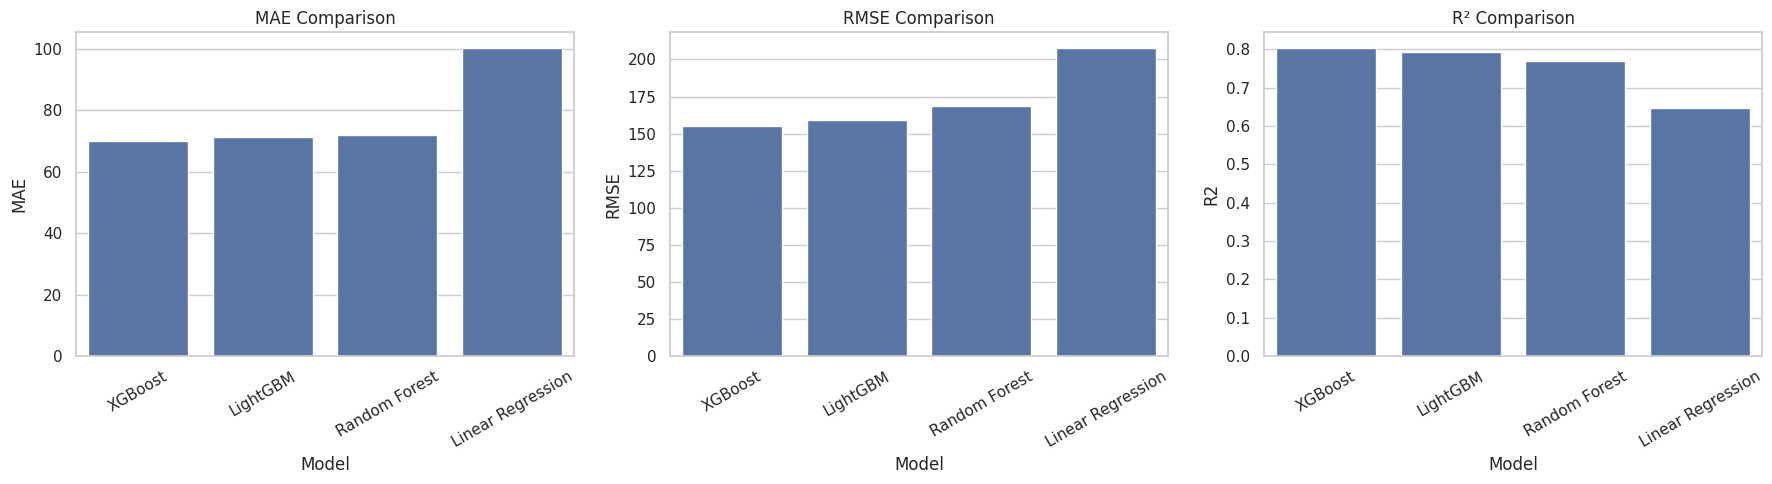

In [ ]:
# Visualize model performance across evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE Comparison")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE Comparison")
axes[1].tick_params(axis="x", rotation=30)

sns.barplot(data=results_df, x="Model", y="R2", ax=axes[2])
axes[2].set_title("R² Comparison")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Actual vs Predicted Demand Comparison Across Models

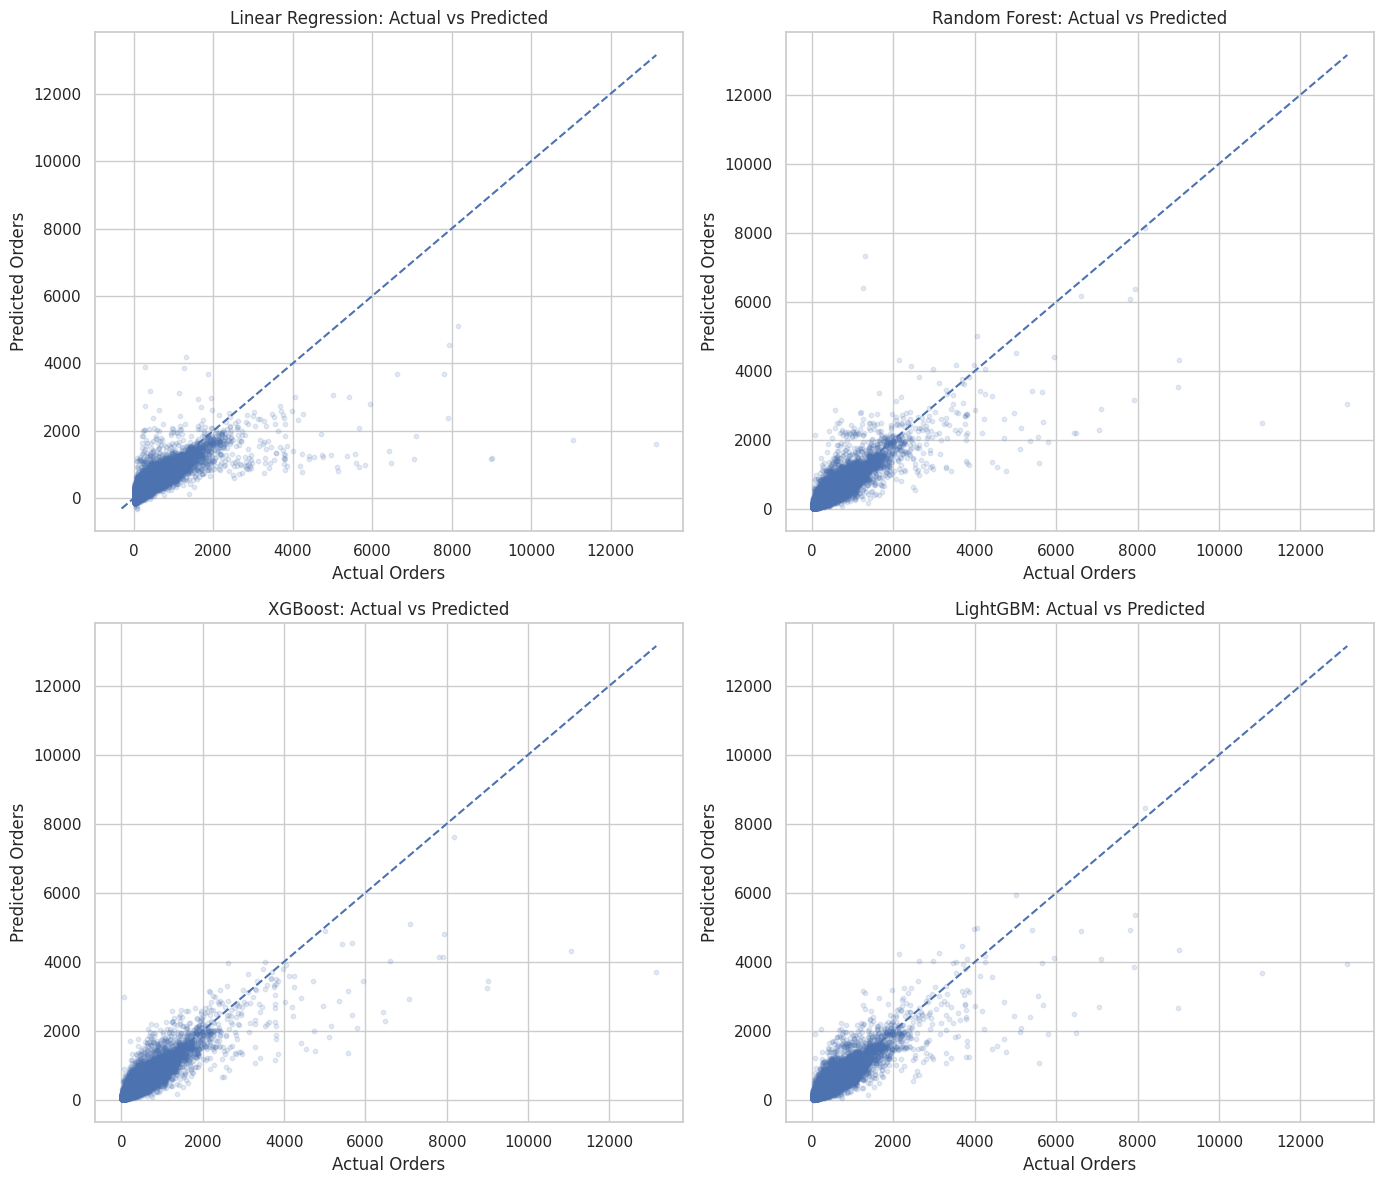

In [ ]:
# Compare actual and predicted demand across all four models
predictions = {
    "Linear Regression": linear_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "LightGBM": lgb_pred
}

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

for ax, (name, pred) in zip(axes.ravel(), predictions.items()):
    ax.scatter(y_val, pred, alpha=0.15, s=10)

    # Add reference line for perfect predictions
    min_value = min(y_val.min(), pred.min())
    max_value = max(y_val.max(), pred.max())

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )

    ax.set_title(f"{name}: Actual vs Predicted")
    ax.set_xlabel("Actual Orders")
    ax.set_ylabel("Predicted Orders")

plt.tight_layout()
plt.show()

Residual Analysis of XGBoost Predictions

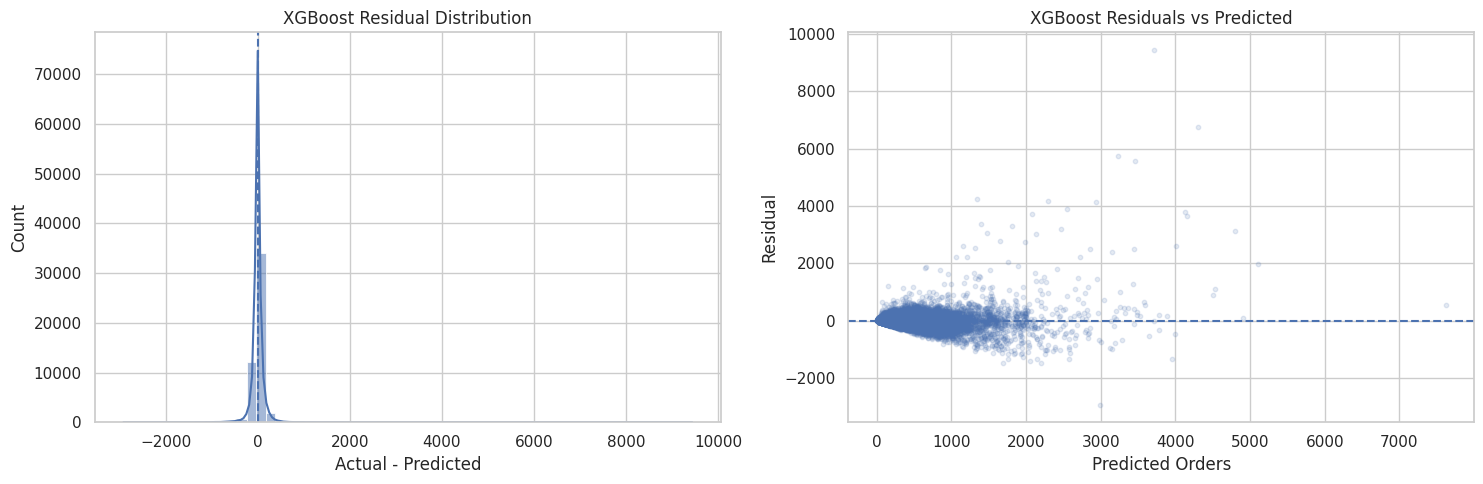

In [ ]:
# Analyze XGBoost prediction errors
xgb_residuals = y_val.values - xgb_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Examine residual distribution
sns.histplot(xgb_residuals, bins=60, kde=True, ax=axes[0])
axes[0].axvline(0, linestyle="--")
axes[0].set_title("XGBoost Residual Distribution")
axes[0].set_xlabel("Actual - Predicted")

# Check residual patterns against predicted demand
axes[1].scatter(
    xgb_pred,
    xgb_residuals,
    alpha=0.15,
    s=10
)
axes[1].axhline(0, linestyle="--")
axes[1].set_title("XGBoost Residuals vs Predicted")
axes[1].set_xlabel("Predicted Orders")
axes[1].set_ylabel("Residual")

plt.tight_layout()
plt.show()

Feature Importance Analysis using XGBoost

,Feature,Importance
14,lag_1,0.137272
18,rolling_mean_4,0.105912
2,emailer_for_promotion,0.073801
38,center_id_43,0.033252
9,discount_percentage,0.031496
155,category_Beverages,0.028151
3,homepage_featured,0.026509
127,meal_id_2290,0.025151
165,category_Sandwich,0.024661
148,cuisine_Continental,0.021184


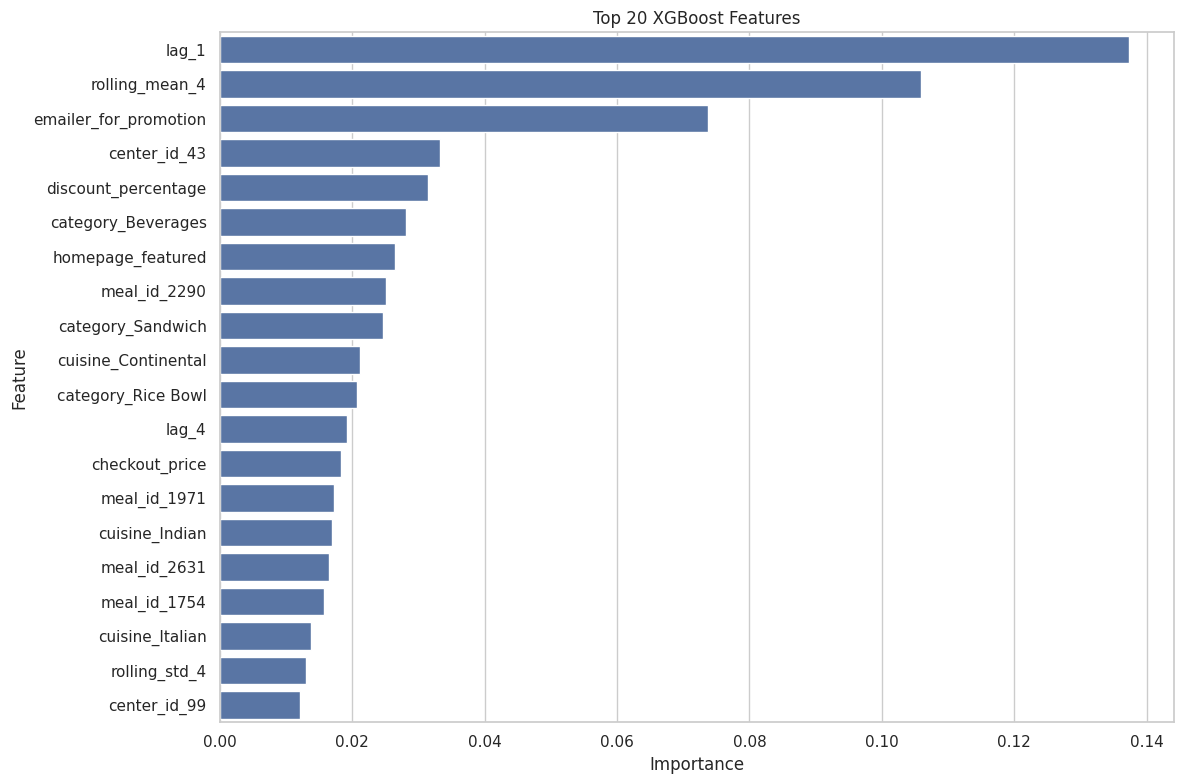

In [ ]:
# Rank features by XGBoost importance
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": xgb_model.feature_importances_
}).sort_values(
    "Importance",
    ascending=False
)

display(feature_importance.head(20))

# Visualize the top 20 most important features
plt.figure(figsize=(12, 8))
sns.barplot(
    data=feature_importance.head(20),
    x="Importance",
    y="Feature"
)
plt.title("Top 20 XGBoost Features")
plt.tight_layout()
plt.show()

Weekly Actual vs Predicted Demand Trend

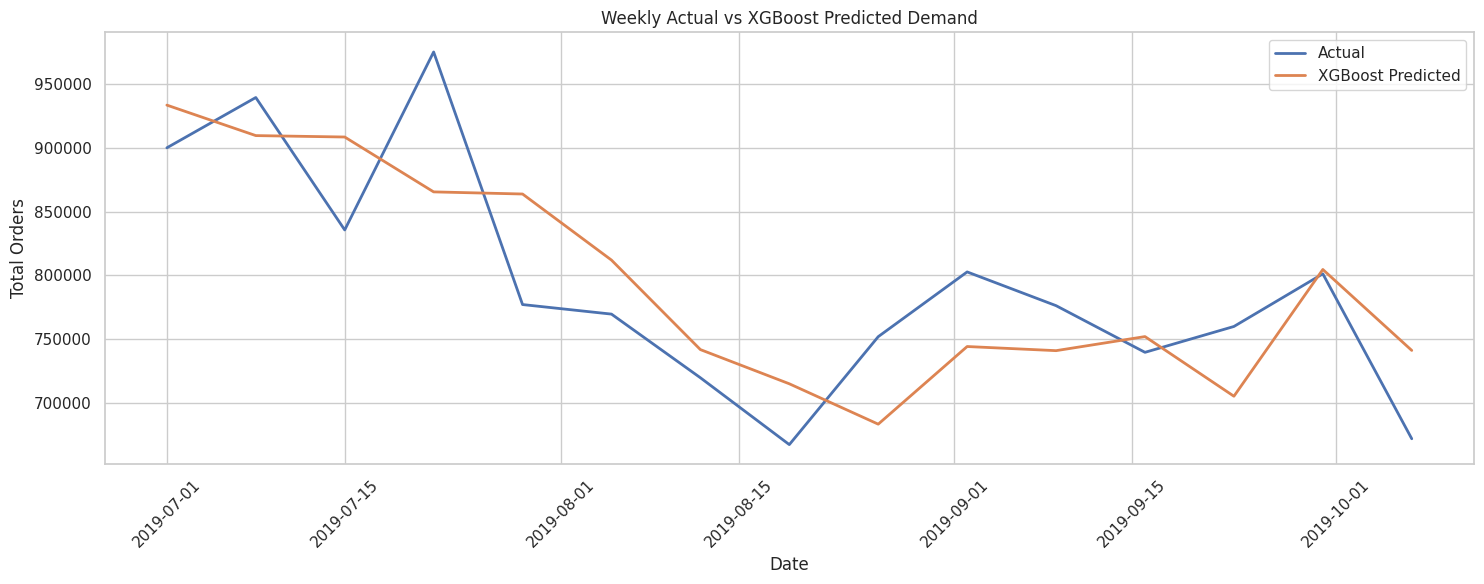

In [ ]:
# Prepare weekly actual and predicted demand for validation
validation_dates = df_train_encoded.loc[val_mask, "date"].reset_index(drop=True)

weekly_validation = pd.DataFrame({
    "date": validation_dates,
    "actual": y_val.reset_index(drop=True),
    "predicted": xgb_pred
})

# Aggregate predictions and actual demand by week
weekly_validation = (
    weekly_validation
    .groupby("date")[["actual", "predicted"]]
    .sum()
    .reset_index()
)

# Compare weekly actual demand with XGBoost predictions
plt.figure(figsize=(15, 6))
plt.plot(
    weekly_validation["date"],
    weekly_validation["actual"],
    label="Actual",
    linewidth=2
)
plt.plot(
    weekly_validation["date"],
    weekly_validation["predicted"],
    label="XGBoost Predicted",
    linewidth=2
)

plt.title("Weekly Actual vs XGBoost Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Total Orders")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Distributional Comparison of Actual and Predicted Demand

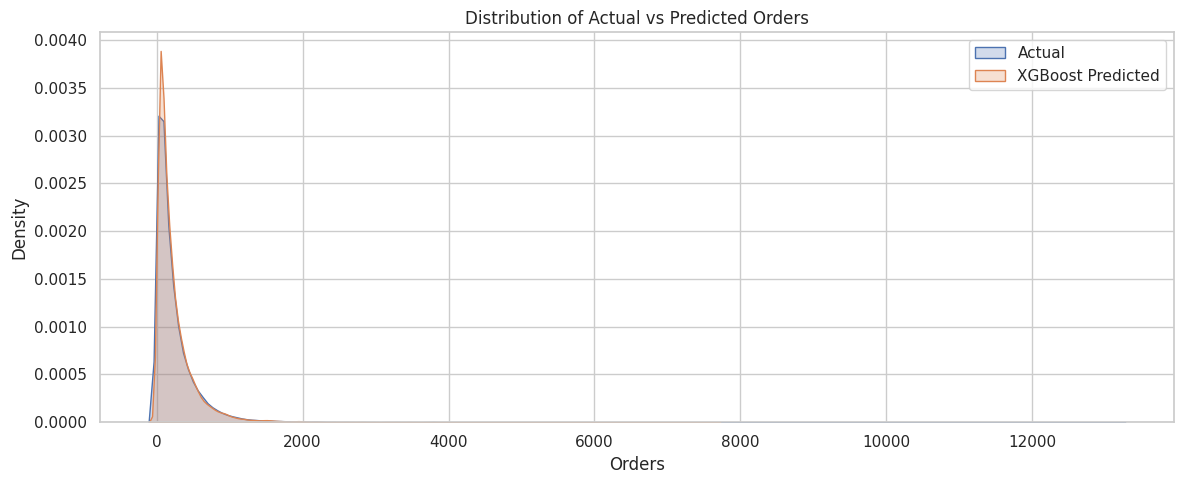

In [ ]:
# Compare the distributions of actual and predicted demand
plt.figure(figsize=(12, 5))

sns.kdeplot(y_val, label="Actual", fill=True)
sns.kdeplot(xgb_pred, label="XGBoost Predicted", fill=True)

plt.title("Distribution of Actual vs Predicted Orders")
plt.xlabel("Orders")
plt.legend()
plt.tight_layout()
plt.show()

Analysis of Demand Underprediction and Overprediction

,Status,Count,Percentage
0,Overprediction,27212,55.191157
1,Underprediction,22093,44.808843


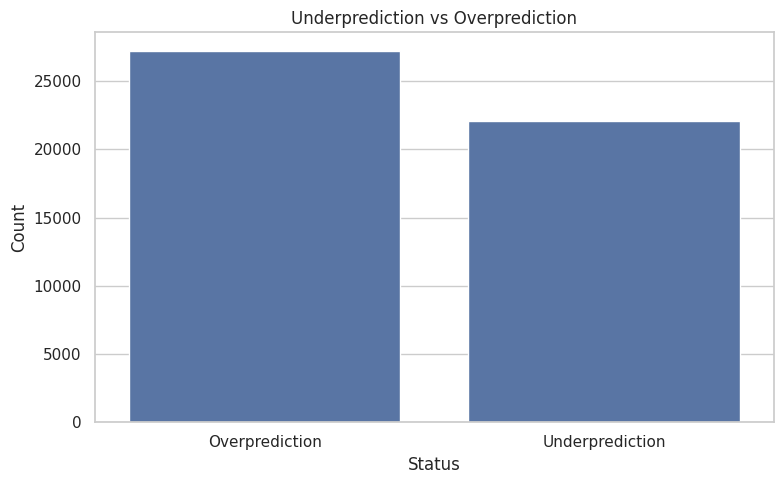

In [ ]:
# Analyze underprediction and overprediction patterns
error_analysis = pd.DataFrame({
    "actual": y_val.values,
    "predicted": xgb_pred
})

error_analysis["error"] = (
    error_analysis["actual"] - error_analysis["predicted"]
)

error_analysis["error_percentage"] = np.where(
    error_analysis["actual"] != 0,
    error_analysis["error"] / error_analysis["actual"] * 100,
    0
)

# Classify prediction errors
error_analysis["status"] = np.where(
    error_analysis["error"] > 0,
    "Underprediction",
    "Overprediction"
)

# Summarize prediction error distribution
error_summary = (
    error_analysis["status"]
    .value_counts()
    .rename_axis("Status")
    .reset_index(name="Count")
)

error_summary["Percentage"] = (
    error_summary["Count"] / len(error_analysis) * 100
)

display(error_summary)

# Compare underprediction and overprediction frequencies
plt.figure(figsize=(8, 5))
sns.barplot(
    data=error_summary,
    x="Status",
    y="Count"
)
plt.title("Underprediction vs Overprediction")
plt.tight_layout()
plt.show()

Identification of High-Error Demand Predictions

,actual,predicted,error,error_percentage,status,abs_error
12248,13150,3710.172607,9439.827393,71.785760,Underprediction,9439.827393
41013,11056,4309.070801,6746.929199,61.025047,Underprediction,6746.929199
1857,8979,3238.153320,5740.846680,63.936370,Underprediction,5740.846680
20731,9019,3454.161865,5564.838135,61.701277,Underprediction,5564.838135
46059,5577,1347.579834,4229.420166,75.836833,Underprediction,4229.420166
34372,6481,2292.777832,4188.222168,64.623085,Underprediction,4188.222168
25786,7060,2931.003662,4128.996338,58.484367,Underprediction,4128.996338
19403,6426,2542.798096,3883.201904,60.429535,Underprediction,3883.201904
1934,7911,4125.664551,3785.335449,47.849013,Underprediction,3785.335449
1119,5804,2083.533936,3720.466064,64.101759,Underprediction,3720.466064


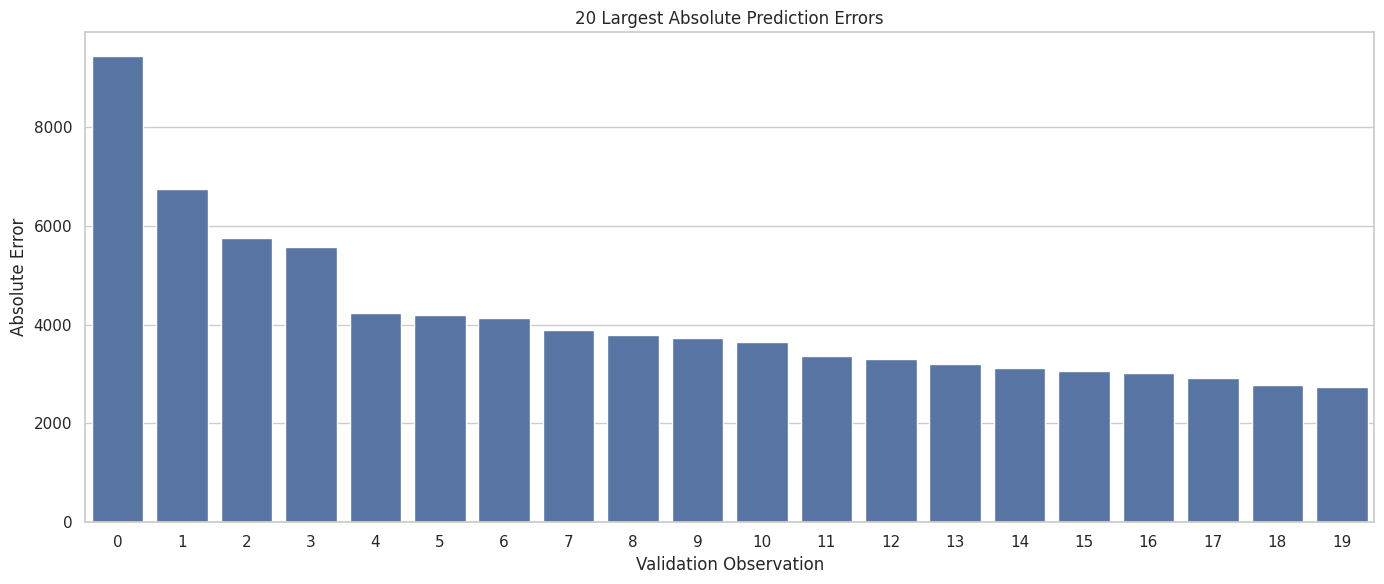

In [ ]:
# Identify observations with the largest prediction errors
worst_predictions = (
    error_analysis
    .assign(abs_error=lambda x: x["error"].abs())
    .sort_values("abs_error", ascending=False)
    .head(20)
)

display(worst_predictions)

# Visualize the 20 largest absolute prediction errors
plt.figure(figsize=(14, 6))
sns.barplot(
    data=worst_predictions,
    x=np.arange(len(worst_predictions)),
    y="abs_error"
)
plt.title("20 Largest Absolute Prediction Errors")
plt.xlabel("Validation Observation")
plt.ylabel("Absolute Error")
plt.tight_layout()
plt.show()

Preliminary Inventory Planning: Overstock and Understock Analysis

In [ ]:
# Evaluate overstock and understock risks and associated costs
SAFETY_STOCK_RATE = 0.10
WASTE_COST_PER_MEAL = 20
STOCKOUT_COST_PER_MEAL = 50

inventory_plan = pd.DataFrame({
    "actual_demand": y_val.values,
    "predicted_demand": xgb_pred
})

# Calculate recommended meal preparation with safety stock
inventory_plan["recommended_preparation"] = np.ceil(
    inventory_plan["predicted_demand"] * (1 + SAFETY_STOCK_RATE)
).astype(int)

inventory_plan["surplus_or_shortage"] = (
    inventory_plan["recommended_preparation"]
    - inventory_plan["actual_demand"]
)

# Classify inventory outcomes
inventory_plan["status"] = np.where(
    inventory_plan["surplus_or_shortage"] < 0,
    "Understock",
    "Overstock"
)

# Quantify surplus and unmet demand
inventory_plan["overstock_meals"] = np.maximum(
    inventory_plan["surplus_or_shortage"],
    0
)

inventory_plan["understock_meals"] = np.maximum(
    -inventory_plan["surplus_or_shortage"],
    0
)

# Estimate waste and stockout costs
inventory_plan["waste_cost"] = (
    inventory_plan["overstock_meals"] * WASTE_COST_PER_MEAL
)

inventory_plan["stockout_cost"] = (
    inventory_plan["understock_meals"] * STOCKOUT_COST_PER_MEAL
)

inventory_plan["total_risk_cost"] = (
    inventory_plan["waste_cost"]
    + inventory_plan["stockout_cost"]
)

display(inventory_plan.head(20))

,actual_demand,predicted_demand,recommended_preparation,surplus_or_shortage,status,overstock_meals,understock_meals,waste_cost,stockout_cost,total_risk_cost
0,1176,802.847412,884,-292,Understock,0,292,0,14600,14600
1,1538,1131.266968,1245,-293,Understock,0,293,0,14650,14650
2,622,1289.461060,1419,797,Overstock,797,0,15940,0,15940
3,782,975.510559,1074,292,Overstock,292,0,5840,0,5840
4,960,856.463562,943,-17,Understock,0,17,0,850,850
5,918,909.269836,1001,83,Overstock,83,0,1660,0,1660
6,703,800.735901,881,178,Overstock,178,0,3560,0,3560
7,513,751.656677,827,314,Overstock,314,0,6280,0,6280
8,824,657.475037,724,-100,Understock,0,100,0,5000,5000
9,1014,771.483887,849,-165,Understock,0,165,0,8250,8250


Summary of Inventory Planning Outcomes

In [ ]:
# Summarize overstock, understock and associated costs

total_overstock = inventory_plan["overstock_meals"].sum()
total_understock = inventory_plan["understock_meals"].sum()
total_waste_cost = inventory_plan["waste_cost"].sum()
total_stockout_cost = inventory_plan["stockout_cost"].sum()
total_risk_cost = inventory_plan["total_risk_cost"].sum()

inventory_summary = pd.DataFrame({
    "Metric": [
        "Total overstock meals",
        "Total understock meals",
        "Illustrative waste cost",
        "Illustrative stockout cost",
        "Total illustrative risk cost"
    ],
    "Value": [
        total_overstock,
        total_understock,
        total_waste_cost,
        total_stockout_cost,
        total_risk_cost
    ]
})

display(inventory_summary)

,Metric,Value
0,Total overstock meals,2478125
1,Total understock meals,1227820
2,Illustrative waste cost,49562500
3,Illustrative stockout cost,61391000
4,Total illustrative risk cost,110953500


Distribution of Inventory Status Categories

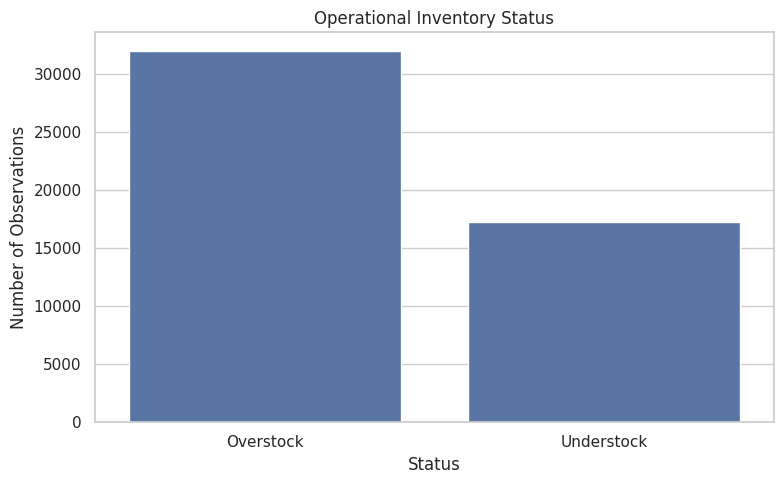

In [ ]:
# Summarize inventory observations by operational status
status_counts = inventory_plan["status"].value_counts()

# Visualize inventory status distribution
plt.figure(figsize=(8, 5))
sns.barplot(
    x=status_counts.index,
    y=status_counts.values
)
plt.title("Operational Inventory Status")
plt.xlabel("Status")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

Comparative Analysis of Overstock and Understock Quantities

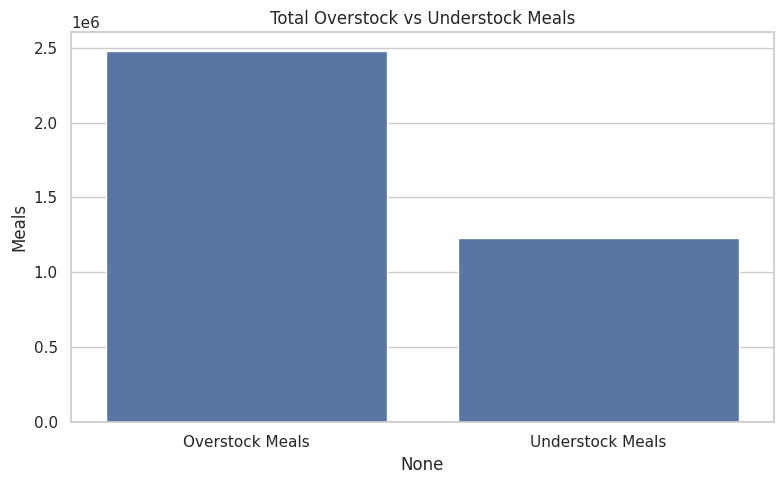

In [ ]:
# Compare total overstock and understock quantities
inventory_totals = pd.Series({
    "Overstock Meals": total_overstock,
    "Understock Meals": total_understock
})

# Visualize inventory imbalance
plt.figure(figsize=(8, 5))
sns.barplot(
    x=inventory_totals.index,
    y=inventory_totals.values
)
plt.title("Total Overstock vs Understock Meals")
plt.ylabel("Meals")
plt.tight_layout()
plt.show()

Illustrative Inventory Preparation Decisions

In [ ]:
# Illustrate operational inventory preparation decisions
sample_decisions = inventory_plan.head(10).copy()

sample_decisions["decision"] = np.where(
    sample_decisions["status"] == "Understock",
    "Increase preparation / investigate demand surge",
    "Prepare planned quantity; monitor potential waste"
)

display(sample_decisions[
    [
        "actual_demand",
        "predicted_demand",
        "recommended_preparation",
        "surplus_or_shortage",
        "status",
        "decision"
    ]
])

,actual_demand,predicted_demand,recommended_preparation,surplus_or_shortage,status,decision
0,1176,802.847412,884,-292,Understock,Increase preparation / investigate demand surge
1,1538,1131.266968,1245,-293,Understock,Increase preparation / investigate demand surge
2,622,1289.461060,1419,797,Overstock,Prepare planned quantity; monitor potential waste
3,782,975.510559,1074,292,Overstock,Prepare planned quantity; monitor potential waste
4,960,856.463562,943,-17,Understock,Increase preparation / investigate demand surge
5,918,909.269836,1001,83,Overstock,Prepare planned quantity; monitor potential waste
6,703,800.735901,881,178,Overstock,Prepare planned quantity; monitor potential waste
7,513,751.656677,827,314,Overstock,Prepare planned quantity; monitor potential waste
8,824,657.475037,724,-100,Understock,Increase preparation / investigate demand surge
9,1014,771.483887,849,-165,Understock,Increase preparation / investigate demand surge


## **Recursive Forecasting and Inventory Decision Evaluation**

Recursive Forecasting Framework and Experimental Configuration

In [ ]:
from collections import defaultdict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_pinball_loss
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor

# Experimental configuration
RANDOM_STATE = 42
QUANTILES = [0.10, 0.50, 0.90]
WASTE_COST_PER_MEAL = 20.0
SHORTAGE_COST_PER_MEAL = 50.0
SAFETY_STOCK_RATE = 0.10
OPTIMAL_QUANTILE = SHORTAGE_COST_PER_MEAL / (SHORTAGE_COST_PER_MEAL + WASTE_COST_PER_MEAL)

FEATURE_COLS = X.columns.tolist()
LAG_COLS = ["lag_1", "lag_2", "lag_3", "lag_4", "rolling_mean_4", "rolling_std_4"]

# Rolling-origin evaluation setup
all_weeks = np.sort(df_train_fe["week_number"].unique())
FOLD_HORIZON = 4
N_FOLDS = 3
required_weeks = FOLD_HORIZON * N_FOLDS

if len(all_weeks) <= required_weeks + 10:
    raise ValueError("Insufficient distinct weeks for the configured rolling-origin evaluation.")

fold_start = len(all_weeks) - required_weeks
rolling_fold_specs = []
for fold_id in range(1, N_FOLDS + 1):
    start = fold_start + (fold_id - 1) * FOLD_HORIZON
    stop = start + FOLD_HORIZON
    rolling_fold_specs.append((
        fold_id,
        all_weeks[:start],
        all_weeks[start:stop]
    ))

# Display fold configurations
print("Distinct weeks:", len(all_weeks))
print("Fold horizon:", FOLD_HORIZON)
for fold_id, train_weeks, valid_weeks in rolling_fold_specs:
    print(f"Fold {fold_id}: train {train_weeks.min()}–{train_weeks.max()} | forecast {valid_weeks.min()}–{valid_weeks.max()}")
print(f"Illustrative cost-optimal quantile: {OPTIMAL_QUANTILE:.3f}")

Distinct weeks: 145
Fold horizon: 4
Fold 1: train 1–133 | forecast 134–137
Fold 2: train 1–137 | forecast 138–141
Fold 3: train 1–141 | forecast 142–145
Illustrative cost-optimal quantile: 0.714


Recursive Historical Feature Generation Utilities

In [ ]:
# Generate lag and rolling-window features from historical demand
def _history_features(history, fallback):
    h = list(history)
    values = {}
    for lag in (1, 2, 3, 4):
        values[f"lag_{lag}"] = h[-lag] if len(h) >= lag else fallback
    recent = h[-4:] if h else [fallback]
    values["rolling_mean_4"] = float(np.mean(recent))
    values["rolling_std_4"] = float(np.std(recent, ddof=1)) if len(recent) > 1 else 0.0
    return values


# Align one-hot encoded features with the training feature set
def _encode_rows(rows, feature_cols):
    encoded = pd.get_dummies(rows.copy(), columns=categorical_cols, drop_first=False)
    return encoded.reindex(columns=feature_cols, fill_value=0)


# Initialize historical demand for each center-meal combination
def _initial_history(train_weeks, target="num_orders"):
    mask = df_train_fe["week_number"].isin(train_weeks)
    hist_df = df_train_fe.loc[mask].sort_values(["center_id", "meal_id", "week_number"])
    history = defaultdict(list)
    for key, grp in hist_df.groupby(GROUP_COLS):
        history[key] = grp[target].astype(float).tolist()
    fallback = float(hist_df[target].median())
    return history, fallback, hist_df


# Recursive forecasting using machine learning models
def recursive_model_forecast(model, train_weeks, forecast_weeks, feature_cols=FEATURE_COLS):
    train_mask = df_train_fe["week_number"].isin(train_weeks)
    train_X = X.loc[train_mask].reindex(columns=feature_cols, fill_value=0)
    train_y = df_train_fe.loc[train_mask, "num_orders"].astype(float)
    model.fit(train_X, train_y)

    history, fallback, _ = _initial_history(train_weeks)
    records = []

    for week in sorted(forecast_weeks):
        rows = df_train_fe.loc[df_train_fe["week_number"].eq(week)].copy()
        history_features = [
            _history_features(history[(row["center_id"], row["meal_id"])], fallback)
            for _, row in rows.iterrows()
        ]
        for col in LAG_COLS:
            rows[col] = [item[col] for item in history_features]

        week_X = _encode_rows(rows, feature_cols)
        predictions = np.maximum(0.0, np.asarray(model.predict(week_X), dtype=float))

        for (_, row), pred in zip(rows.iterrows(), predictions):
            key = (row["center_id"], row["meal_id"])
            records.append({
                "week_number": int(row["week_number"]),
                "center_id": row["center_id"],
                "meal_id": row["meal_id"],
                "actual": float(row["num_orders"]),
                "prediction": float(pred)
            })
            history[key].append(float(pred))

    return pd.DataFrame(records), model


# Recursive naive and seasonal-naive forecasting baselines
def recursive_naive_forecast(train_weeks, forecast_weeks, seasonal_lag=None):
    history, fallback, _ = _initial_history(train_weeks)
    records = []

    for week in sorted(forecast_weeks):
        rows = df_train_fe.loc[df_train_fe["week_number"].eq(week)].copy()
        pending = []
        for _, row in rows.iterrows():
            key = (row["center_id"], row["meal_id"])
            h = history[key]
            if seasonal_lag is not None and len(h) >= seasonal_lag:
                pred = h[-seasonal_lag]
            elif h:
                pred = h[-1]
            else:
                pred = fallback
            pending.append((key, row, max(0.0, float(pred))))

        for key, row, pred in pending:
            records.append({
                "week_number": int(row["week_number"]),
                "center_id": row["center_id"],
                "meal_id": row["meal_id"],
                "actual": float(row["num_orders"]),
                "prediction": pred
            })
        for key, row, pred in pending:
            history[key].append(pred)

    return pd.DataFrame(records)


# Evaluate forecasting performance
def forecast_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }


# LightGBM model configuration
def make_lgbm_model():
    return LGBMRegressor(
        objective="regression", n_estimators=300, learning_rate=0.04,
        num_leaves=31, subsample=0.85, colsample_bytree=0.85,
        random_state=RANDOM_STATE, n_jobs=-1, verbosity=-1
    )


# XGBoost model configuration
def make_xgb_model():
    return XGBRegressor(
        objective="reg:squarederror", n_estimators=300, learning_rate=0.05,
        max_depth=6, min_child_weight=3, subsample=0.8,
        colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1
    )

Rolling-Origin Evaluation and Comparative Model Forecasting

Evaluating fold 1/3...
Evaluating fold 2/3...
Evaluating fold 3/3...


,Fold,Model,MAE,RMSE,R2
0,1,Last-value baseline,146.587,444.446,-0.490
1,1,4-observation naive baseline,148.657,444.190,-0.489
2,1,LightGBM,81.151,177.891,0.761
3,1,XGBoost,81.253,184.108,0.744
4,2,Last-value baseline,92.056,164.376,0.654
5,2,4-observation naive baseline,114.167,269.588,0.070
6,2,LightGBM,74.759,126.519,0.795
7,2,XGBoost,71.642,121.548,0.811
8,3,Last-value baseline,94.011,173.194,0.604
9,3,4-observation naive baseline,93.266,162.871,0.650


,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean
2,LightGBM,73.784,7.901,136.510,37.400,0.803
3,XGBoost,72.888,7.817,137.822,40.669,0.801
1,Last-value baseline,110.885,30.935,260.672,159.214,0.256
0,4-observation naive baseline,118.697,27.972,292.216,142.018,0.077


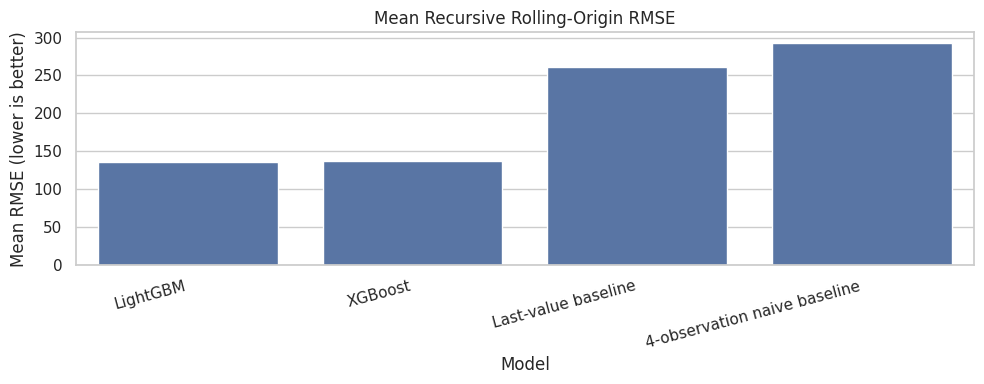

Selected primary model: LightGBM
Selection criterion: lowest mean RMSE across identical rolling-origin folds.


In [ ]:
# Rolling-origin evaluation across baseline and ML models
rolling_model_rows = []
rolling_model_predictions = []

for fold_id, train_weeks, valid_weeks in rolling_fold_specs:
    print(f"Evaluating fold {fold_id}/{N_FOLDS}...")

    last_pred = recursive_naive_forecast(train_weeks, valid_weeks)
    seasonal_pred = recursive_naive_forecast(train_weeks, valid_weeks, seasonal_lag=4)
    lgb_pred, _ = recursive_model_forecast(make_lgbm_model(), train_weeks, valid_weeks)
    xgb_pred_recursive, _ = recursive_model_forecast(make_xgb_model(), train_weeks, valid_weeks)

    fold_frames = [
        ("Last-value baseline", last_pred),
        ("4-observation naive baseline", seasonal_pred),
        ("LightGBM", lgb_pred),
        ("XGBoost", xgb_pred_recursive)
    ]

    # Calculate and store fold-wise performance metrics
    for model_name, frame in fold_frames:
        metrics = forecast_metrics(frame["actual"], frame["prediction"])
        rolling_model_rows.append({"Fold": fold_id, "Model": model_name, **metrics})
        saved = frame.copy()
        saved["Fold"] = fold_id
        saved["Model"] = model_name
        rolling_model_predictions.append(saved)

rolling_model_metrics = pd.DataFrame(rolling_model_rows)
rolling_model_predictions = pd.concat(rolling_model_predictions, ignore_index=True)

display(rolling_model_metrics.round(3))

# Aggregate performance across rolling folds
rolling_model_summary = (
    rolling_model_metrics.groupby("Model")
    .agg(
        MAE_mean=("MAE", "mean"), MAE_std=("MAE", "std"),
        RMSE_mean=("RMSE", "mean"), RMSE_std=("RMSE", "std"),
        R2_mean=("R2", "mean")
    )
    .reset_index()
    .sort_values("RMSE_mean")
)
display(rolling_model_summary.round(3))

# Compare mean RMSE across models
plt.figure(figsize=(10, 4))
sns.barplot(data=rolling_model_summary, x="Model", y="RMSE_mean")
plt.title("Mean Recursive Rolling-Origin RMSE")
plt.ylabel("Mean RMSE (lower is better)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

# Select the primary model based on mean RMSE
model_candidates = rolling_model_summary[
    rolling_model_summary["Model"].isin(["LightGBM", "XGBoost"])
].copy()
PRIMARY_MODEL_NAME = (
    model_candidates.sort_values("RMSE_mean").iloc[0]["Model"]
)
print("Selected primary model:", PRIMARY_MODEL_NAME)
print("Selection criterion: lowest mean RMSE across identical rolling-origin folds.")

Quantile Regression Model Configuration

In [ ]:
# Configure LightGBM quantile regression models
def make_quantile_lgbm(alpha):
    return LGBMRegressor(
        objective="quantile", alpha=float(alpha), n_estimators=300,
        learning_rate=0.04, num_leaves=31, subsample=0.85,
        colsample_bytree=0.85, random_state=RANDOM_STATE,
        n_jobs=-1, verbosity=-1
    )


# Recursive probabilistic forecasting using quantile regression
def recursive_quantile_forecast(train_weeks, forecast_weeks, quantiles):
    train_mask = df_train_fe["week_number"].isin(train_weeks)
    train_X = X.loc[train_mask].reindex(columns=FEATURE_COLS, fill_value=0)
    train_y = df_train_fe.loc[train_mask, "num_orders"].astype(float)

    # Train separate models for each quantile
    models = {}
    for q in quantiles:
        model = make_quantile_lgbm(q)
        model.fit(train_X, train_y)
        models[q] = model

    history, fallback, _ = _initial_history(train_weeks)
    records = []

    for week in sorted(forecast_weeks):
        rows = df_train_fe.loc[df_train_fe["week_number"].eq(week)].copy()
        history_features = [
            _history_features(history[(row["center_id"], row["meal_id"])], fallback)
            for _, row in rows.iterrows()
        ]
        for col in LAG_COLS:
            rows[col] = [item[col] for item in history_features]

        week_X = _encode_rows(rows, FEATURE_COLS)

        # Generate non-negative, monotonically ordered quantile predictions
        ordered_quantiles = sorted(quantiles)
        matrix = np.column_stack([
            np.maximum(0.0, np.asarray(models[q].predict(week_X), dtype=float))
            for q in ordered_quantiles
        ])
        matrix = np.maximum.accumulate(matrix, axis=1)

        median_idx = min(range(len(ordered_quantiles)), key=lambda i: abs(ordered_quantiles[i] - 0.50))
        for i, (_, row) in enumerate(rows.iterrows()):
            record = {
                "week_number": int(row["week_number"]),
                "center_id": row["center_id"],
                "meal_id": row["meal_id"],
                "actual": float(row["num_orders"])
            }
            for j, q in enumerate(ordered_quantiles):
                record[f"q{q:.4f}"] = float(matrix[i, j])
            records.append(record)

        # Update history using median predictions
        for i, (_, row) in enumerate(rows.iterrows()):
            history[(row["center_id"], row["meal_id"])].append(float(matrix[i, median_idx]))

    return pd.DataFrame(records), models


# Evaluate quantile forecasts across rolling-origin folds
QUANTILE_LEVELS = sorted(set([0.10, 0.50, 0.90, round(OPTIMAL_QUANTILE, 4)]))
quantile_fold_frames = []
quantile_score_rows = []

for fold_id, train_weeks, valid_weeks in rolling_fold_specs:
    print(f"Quantile forecasting fold {fold_id}/{N_FOLDS}...")
    q_frame, q_models = recursive_quantile_forecast(train_weeks, valid_weeks, QUANTILE_LEVELS)
    q_frame["Fold"] = fold_id
    quantile_fold_frames.append(q_frame)

    # Calculate quantile-specific pinball loss
    for q in QUANTILE_LEVELS:
        col = f"q{q:.4f}"
        quantile_score_rows.append({
            "Fold": fold_id,
            "Quantile": q,
            "Pinball loss": mean_pinball_loss(q_frame["actual"], q_frame[col], alpha=q)
        })

rolling_quantile_results = pd.concat(quantile_fold_frames, ignore_index=True)
quantile_score_table = pd.DataFrame(quantile_score_rows)
display(quantile_score_table.round(4))

# Evaluate prediction interval coverage and width
q10_col, q90_col = "q0.1000", "q0.9000"
rolling_quantile_results["interval_covered"] = (
    (rolling_quantile_results["actual"] >= rolling_quantile_results[q10_col]) &
    (rolling_quantile_results["actual"] <= rolling_quantile_results[q90_col])
)
coverage_by_fold = (
    rolling_quantile_results.groupby("Fold")
    .agg(
        Coverage=("interval_covered", "mean"),
        Mean_interval_width=(q90_col, lambda s: np.nan)
    )
    .reset_index()
)
coverage_by_fold["Mean_interval_width"] = (
    rolling_quantile_results.assign(
        interval_width=rolling_quantile_results[q90_col] - rolling_quantile_results[q10_col]
    ).groupby("Fold")["interval_width"].mean().values
)
coverage_by_fold["Coverage"] *= 100
display(coverage_by_fold.round(2))

# Overall prediction interval performance
overall_coverage = 100 * rolling_quantile_results["interval_covered"].mean()
overall_width = (rolling_quantile_results[q90_col] - rolling_quantile_results[q10_col]).mean()
print(f"Empirical q10–q90 coverage: {overall_coverage:.2f}% (nominal: 80%)")
print(f"Mean interval width: {overall_width:.2f} meals")

Quantile forecasting fold 1/3...
Quantile forecasting fold 2/3...
Quantile forecasting fold 3/3...


,Fold,Quantile,Pinball loss
0,1,0.1000,16.5119
1,1,0.5000,41.0052
2,1,0.7143,37.9422
3,1,0.9000,23.4141
4,2,0.1000,13.4943
5,2,0.5000,36.1868
6,2,0.7143,33.5927
7,2,0.9000,20.0649
8,3,0.1000,13.1704
9,3,0.5000,32.5651


,Fold,Coverage,Mean_interval_width
0,1,75.78,208.36
1,2,73.67,186.77
2,3,79.29,203.68


Empirical q10–q90 coverage: 76.24% (nominal: 80%)
Mean interval width: 199.60 meals


Cost-Sensitive Inventory Policy Evaluation

,Fold,Policy,Total cost (₹),Cost per observation (₹),Excess meals,Unmet meals,No-shortage observation rate (%),Mean prepared meals
0,1,Median forecast,42436840.0,3227.87,381022.0,696328.0,44.26,222.58
1,1,Fixed 10% safety stock,38336440.0,2915.98,530942.0,554352.0,52.33,244.78
2,1,Cost-optimal quantile,34885900.0,2653.53,720395.0,409560.0,64.90,270.20
3,2,Median forecast,38270850.0,2909.89,310025.0,641407.0,47.90,202.77
4,2,Fixed 10% safety stock,33713480.0,2563.37,434964.0,500284.0,55.78,223.00
5,2,Cost-optimal quantile,30907690.0,2350.04,619227.0,370463.0,67.12,246.88
6,3,Median forecast,28922560.0,2205.64,460273.0,394342.0,55.45,231.73
7,3,Fixed 10% safety stock,26856330.0,2048.07,647399.0,278167.0,64.39,254.86
8,3,Cost-optimal quantile,26731890.0,2038.58,840737.0,198343.0,74.84,275.69


,Policy,Mean_cost,SD_cost,Mean_cost_per_observation,Mean_excess,Mean_unmet,Mean_no_shortage_rate
0,Cost-optimal quantile,30841826.67,4077403.98,2347.38,726786.33,326122.00,68.95
1,Fixed 10% safety stock,32968750.00,5776175.07,2509.14,537768.33,444267.67,57.50
2,Median forecast,36543416.67,6920762.99,2781.13,383773.33,577359.00,49.20


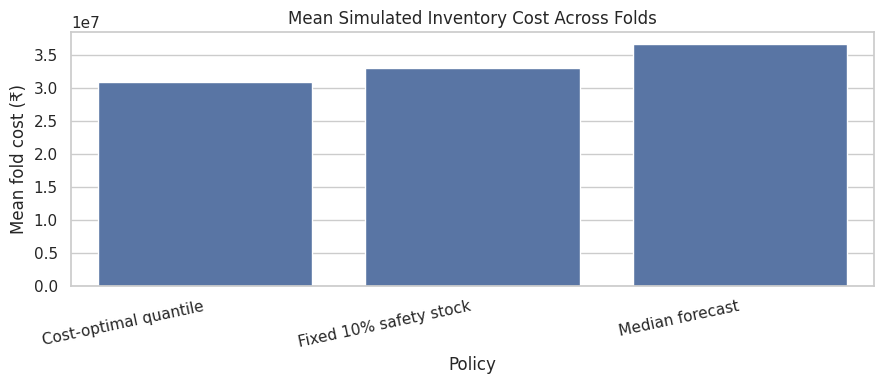

In [ ]:
# Evaluate inventory preparation costs and service levels
def score_inventory_policy(actual, prepared, shortage_cost, excess_cost):
    actual = np.asarray(actual, dtype=float)
    prepared = np.maximum(0, np.asarray(prepared, dtype=float))
    excess = np.maximum(prepared - actual, 0)
    shortage = np.maximum(actual - prepared, 0)
    total_cost = excess_cost * excess.sum() + shortage_cost * shortage.sum()

    return {
        "Total cost (₹)": float(total_cost),
        "Cost per observation (₹)": float(total_cost / len(actual)),
        "Excess meals": float(excess.sum()),
        "Unmet meals": float(shortage.sum()),
        "No-shortage observation rate (%)": float(100 * np.mean(shortage == 0)),
        "Mean prepared meals": float(prepared.mean())
    }


# Define inventory preparation policies
tau_col = f"q{OPTIMAL_QUANTILE:.4f}"
if tau_col not in rolling_quantile_results.columns:
    raise KeyError(f"Cost-optimal quantile output {tau_col} is missing.")

policy_eval = rolling_quantile_results.copy()
policy_eval["Median forecast"] = np.ceil(policy_eval["q0.5000"].clip(lower=0))
policy_eval["Fixed 10% safety stock"] = np.ceil(
    policy_eval["q0.5000"].clip(lower=0) * (1 + SAFETY_STOCK_RATE)
)
policy_eval["Cost-optimal quantile"] = np.ceil(policy_eval[tau_col].clip(lower=0))

# Evaluate inventory policies across folds
policy_rows = []
for fold_id, fold in policy_eval.groupby("Fold"):
    for policy_name in ["Median forecast", "Fixed 10% safety stock", "Cost-optimal quantile"]:
        scores = score_inventory_policy(
            fold["actual"], fold[policy_name],
            SHORTAGE_COST_PER_MEAL, WASTE_COST_PER_MEAL
        )
        policy_rows.append({"Fold": fold_id, "Policy": policy_name, **scores})

rolling_policy_results = pd.DataFrame(policy_rows)
display(rolling_policy_results.round(2))

# Compare aggregate inventory policy performance
policy_summary = (
    rolling_policy_results.groupby("Policy")
    .agg(
        Mean_cost=("Total cost (₹)", "mean"),
        SD_cost=("Total cost (₹)", "std"),
        Mean_cost_per_observation=("Cost per observation (₹)", "mean"),
        Mean_excess=("Excess meals", "mean"),
        Mean_unmet=("Unmet meals", "mean"),
        Mean_no_shortage_rate=("No-shortage observation rate (%)", "mean")
    )
    .reset_index()
    .sort_values("Mean_cost")
)
display(policy_summary.round(2))

# Compare mean inventory costs across policies
plt.figure(figsize=(9, 4))
sns.barplot(data=policy_summary, x="Policy", y="Mean_cost")
plt.title("Mean Simulated Inventory Cost Across Folds")
plt.ylabel("Mean fold cost (₹)")
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.show()

Sensitivity Analysis of Shortage and Excess Inventory Costs

In [ ]:
# Sensitivity analysis under varying shortage and waste costs
sensitivity_rows = []
for shortage_cost in [10, 20, 50, 100, 200]:
    for excess_cost in [10, 20, 40, 100]:
        tau = shortage_cost / (shortage_cost + excess_cost)

        # Select the nearest available fitted quantile
        nearest_q = min(QUANTILE_LEVELS, key=lambda q: abs(q - tau))
        q_col = f"q{nearest_q:.4f}"

        for fold_id, fold in policy_eval.groupby("Fold"):
            candidates = {
                "Median forecast": fold["Median forecast"],
                "Fixed 10% safety stock": fold["Fixed 10% safety stock"],
                f"Nearest fitted quantile ({nearest_q:.2f})": np.ceil(fold[q_col].clip(lower=0))
            }
            for name, prepared in candidates.items():
                scores = score_inventory_policy(
                    fold["actual"], prepared, shortage_cost, excess_cost
                )
                sensitivity_rows.append({
                    "Fold": fold_id, "Shortage cost": shortage_cost,
                    "Waste cost": excess_cost, "Target quantile": tau,
                    "Policy": name, **scores
                })

cost_sensitivity = pd.DataFrame(sensitivity_rows)

# Identify the lowest-cost policy for each cost scenario
sensitivity_summary = (
    cost_sensitivity.groupby(["Shortage cost", "Waste cost", "Policy"], as_index=False)
    .agg(Mean_cost=("Total cost (₹)", "mean"))
)
sensitivity_winners = (
    sensitivity_summary.sort_values("Mean_cost")
    .groupby(["Shortage cost", "Waste cost"], as_index=False)
    .first()
)
display(sensitivity_winners.round(2))

,Shortage cost,Waste cost,Policy,Mean_cost
0,10,10,Median forecast,9.611323e+06
1,10,20,Median forecast,1.344906e+07
2,10,40,Nearest fitted quantile (0.10),1.629969e+07
3,10,100,Nearest fitted quantile (0.10),1.943867e+07
4,20,10,Nearest fitted quantile (0.71),1.379030e+07
5,20,20,Nearest fitted quantile (0.50),1.922265e+07
6,20,40,Median forecast,2.689811e+07
7,20,100,Nearest fitted quantile (0.10),3.364571e+07
8,50,10,Nearest fitted quantile (0.90),2.060214e+07
9,50,20,Nearest fitted quantile (0.71),3.084183e+07


Feature Ablation Study: Contribution of Historical Demand Features

In [ ]:
# Feature ablation analysis
ablation_fold_id, ablation_train_weeks, ablation_valid_weeks = rolling_fold_specs[-1]
ablation_rows = []

for label, cols in [
    ("Full feature set", FEATURE_COLS),
    ("Without lag/rolling features", [c for c in FEATURE_COLS if c not in LAG_COLS])
]:
    ablation_model = make_lgbm_model()
    predictions, _ = recursive_model_forecast(
        ablation_model, ablation_train_weeks, ablation_valid_weeks, feature_cols=cols
    )
    metrics = forecast_metrics(predictions["actual"], predictions["prediction"])
    ablation_rows.append({"Feature set": label, **metrics})

# Compare forecasting performance across feature sets
ablation_results = pd.DataFrame(ablation_rows)
display(ablation_results.round(3))

,Feature set,MAE,RMSE,R2
0,Full feature set,65.441,105.121,0.854
1,Without lag/rolling features,80.887,129.708,0.778


Error Analysis of the Selected Forecasting Model

In [ ]:
# Error analysis across fulfilment centers and meal categories
primary_predictions = rolling_model_predictions[
    rolling_model_predictions["Model"] == PRIMARY_MODEL_NAME
].copy()
primary_predictions["absolute_error"] = (
    primary_predictions["actual"] - primary_predictions["prediction"]
).abs()
primary_predictions["signed_error"] = (
    primary_predictions["prediction"] - primary_predictions["actual"]
)

# Identify fulfilment centers with the highest prediction errors
center_error = (
    primary_predictions.groupby("center_id")
    .agg(Observations=("actual", "size"), MAE=("absolute_error", "mean"),
         Mean_bias=("signed_error", "mean"))
    .reset_index().sort_values("MAE", ascending=False)
)

# Identify meal categories with the highest prediction errors
meal_error = (
    primary_predictions.groupby("meal_id")
    .agg(Observations=("actual", "size"), MAE=("absolute_error", "mean"),
         Mean_bias=("signed_error", "mean"))
    .reset_index().sort_values("MAE", ascending=False)
)

print("Highest-error fulfilment centers")
display(center_error.head(10))
print("Highest-error meal categories")
display(meal_error.head(10))

Highest-error fulfilment centers


,center_id,Observations,MAE,Mean_bias
2,13,612,142.680867,-22.252743
18,43,601,135.217993,-30.254458
63,137,591,126.329204,-18.916518
0,10,610,114.265171,-35.153338
21,52,603,107.307983,-22.686418
31,67,602,100.834461,-10.524744
7,24,549,96.434902,-38.741464
50,99,574,93.905577,5.864163
20,51,598,90.379102,10.222205
53,104,571,89.364877,-4.297066


Highest-error meal categories


,meal_id,Observations,MAE,Mean_bias
30,2290,924,293.690698,-69.081759
1,1109,924,159.003312,-56.504073
15,1727,924,149.993801,38.792921
26,1993,924,139.959368,18.698045
24,1962,924,128.578770,-17.528207
16,1754,924,127.149893,-76.826498
22,1885,923,118.843602,-29.657961
46,2707,924,113.233242,-39.526451
25,1971,920,111.094129,44.408729
48,2826,924,101.778348,-52.207960


Final Model Training and Recursive Test-Period Forecasting

In [ ]:
# Recursive forecasting on the unseen test dataset
def recursive_test_forecast(model, train_weeks, test_frame, feature_cols):
    train_mask = df_train_fe["week_number"].isin(train_weeks)
    train_X = X.loc[train_mask].reindex(columns=feature_cols, fill_value=0)
    train_y = df_train_fe.loc[train_mask, "num_orders"].astype(float)
    model.fit(train_X, train_y)

    history, fallback, _ = _initial_history(train_weeks)
    test_rows = test_frame.copy().sort_values(
        ["week_number", "center_id", "meal_id"]
    ).reset_index(drop=True)

    # Generate predictions sequentially using previously predicted demand
    for week in sorted(test_rows["week_number"].unique()):
        mask = test_rows["week_number"].eq(week)
        rows = test_rows.loc[mask].copy()
        history_features = [
            _history_features(history[(row["center_id"], row["meal_id"])], fallback)
            for _, row in rows.iterrows()
        ]
        for col in LAG_COLS:
            rows[col] = [item[col] for item in history_features]

        week_X = _encode_rows(rows, feature_cols)
        predictions = np.maximum(0.0, np.asarray(model.predict(week_X), dtype=float))
        test_rows.loc[mask, "predicted_num_orders"] = predictions

        for (_, row), pred in zip(rows.iterrows(), predictions):
            history[(row["center_id"], row["meal_id"])].append(float(pred))

    return test_rows, model


# Initialize the selected primary forecasting model
if PRIMARY_MODEL_NAME == "LightGBM":
    final_model = make_lgbm_model()
    final_feature_cols = FEATURE_COLS
elif PRIMARY_MODEL_NAME == "XGBoost":
    final_model = make_xgb_model()
    final_feature_cols = FEATURE_COLS
else:
    raise ValueError(f"Unexpected primary model: {PRIMARY_MODEL_NAME}")

# Generate final test-set predictions
test_forecast, final_model = recursive_test_forecast(
    final_model, all_weeks, df_test_fe, final_feature_cols
)

# Prepare and export the submission file
submission = pd.DataFrame({
    "id": test_forecast["id"].astype(int),
    "num_orders": np.maximum(
        0, np.rint(test_forecast["predicted_num_orders"])
    ).astype(int)
})

submission_path = "/content/submission_final.csv"
submission.to_csv(submission_path, index=False)

print("Selected model:", PRIMARY_MODEL_NAME)
print("Submission saved:", submission_path)
print("Submission shape:", submission.shape)
display(submission.head())

Selected model: LightGBM
Submission saved: /content/submission_final.csv
Submission shape: (32573, 2)


,id,num_orders
0,1177098,937
1,1287288,1382
2,1386036,390
3,1391435,125
4,1330467,216


Weekly Demand Forecast Profile for the Test Period

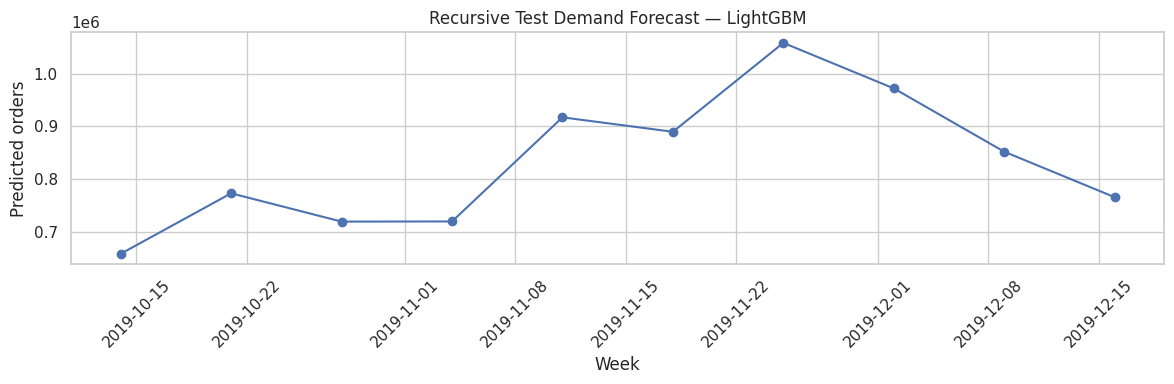

In [ ]:
# Weekly demand forecast profile for the unseen test period
test_weekly = (
    test_forecast.groupby("date")["predicted_num_orders"]
    .sum().reset_index()
)

plt.figure(figsize=(12, 4))
plt.plot(test_weekly["date"], test_weekly["predicted_num_orders"], marker="o")
plt.title(f"Recursive Test Demand Forecast — {PRIMARY_MODEL_NAME}")
plt.xlabel("Week")
plt.ylabel("Predicted orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Consolidated Model Results and Experimental Data Export

In [ ]:
# Consolidate and export research results
model_summary_export = rolling_model_summary.copy()
policy_summary_export = policy_summary.copy()

display(model_summary_export.round(3))
display(policy_summary_export.round(2))

# Export experimental results and evaluation tables
model_summary_export.to_csv("/content/rolling_origin_model_summary.csv", index=False)
rolling_model_metrics.to_csv("/content/rolling_origin_model_metrics.csv", index=False)
quantile_score_table.to_csv("/content/quantile_pinball_scores.csv", index=False)
coverage_by_fold.to_csv("/content/quantile_interval_coverage.csv", index=False)
rolling_policy_results.to_csv("/content/rolling_origin_inventory_results.csv", index=False)
policy_summary_export.to_csv("/content/inventory_policy_summary.csv", index=False)
cost_sensitivity.to_csv("/content/inventory_cost_sensitivity.csv", index=False)
ablation_results.to_csv("/content/feature_ablation_results.csv", index=False)
center_error.to_csv("/content/center_error_analysis.csv", index=False)
meal_error.to_csv("/content/meal_error_analysis.csv", index=False)

# Compile key research findings
selected_model_row = model_candidates.loc[
    model_candidates["Model"].eq(PRIMARY_MODEL_NAME)
].iloc[0]

research_summary = pd.DataFrame([{
    "Selected primary model": PRIMARY_MODEL_NAME,
    "Selected model mean rolling-origin RMSE": float(selected_model_row["RMSE_mean"]),
    "Selected model mean rolling-origin MAE": float(selected_model_row["MAE_mean"]),
    "Q10-Q90 coverage (%)": float(overall_coverage),
    "Q10-Q90 mean width": float(overall_width),
    "Lowest mean-cost inventory policy": str(policy_summary.iloc[0]["Policy"]),
    "Lowest mean fold cost (INR)": float(policy_summary.iloc[0]["Mean_cost"]),
    "Illustrative shortage cost (INR/meal)": SHORTAGE_COST_PER_MEAL,
    "Illustrative waste cost (INR/meal)": WASTE_COST_PER_MEAL
}])
display(research_summary.round(3))
research_summary.to_csv("/content/research_summary.csv", index=False)

# Confirm export completion
print("Research tables and final submission saved in /content/.")

,Model,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean
2,LightGBM,73.784,7.901,136.510,37.400,0.803
3,XGBoost,72.888,7.817,137.822,40.669,0.801
1,Last-value baseline,110.885,30.935,260.672,159.214,0.256
0,4-observation naive baseline,118.697,27.972,292.216,142.018,0.077


,Policy,Mean_cost,SD_cost,Mean_cost_per_observation,Mean_excess,Mean_unmet,Mean_no_shortage_rate
0,Cost-optimal quantile,30841826.67,4077403.98,2347.38,726786.33,326122.00,68.95
1,Fixed 10% safety stock,32968750.00,5776175.07,2509.14,537768.33,444267.67,57.50
2,Median forecast,36543416.67,6920762.99,2781.13,383773.33,577359.00,49.20


,Selected primary model,Selected model mean rolling-origin RMSE,Selected model mean rolling-origin MAE,Q10-Q90 coverage (%),Q10-Q90 mean width,Lowest mean-cost inventory policy,Lowest mean fold cost (INR),Illustrative shortage cost (INR/meal),Illustrative waste cost (INR/meal)
0,LightGBM,136.51,73.784,76.243,199.599,Cost-optimal quantile,3.084183e+07,50.0,20.0


Research tables and final submission saved in /content/.
